<a href="https://colab.research.google.com/github/laksh-ops/EVerse/blob/main/mainw10_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

22050,1,5.333378684807256
22050,1,45.844897959183676
22050,1,119.87591836734694


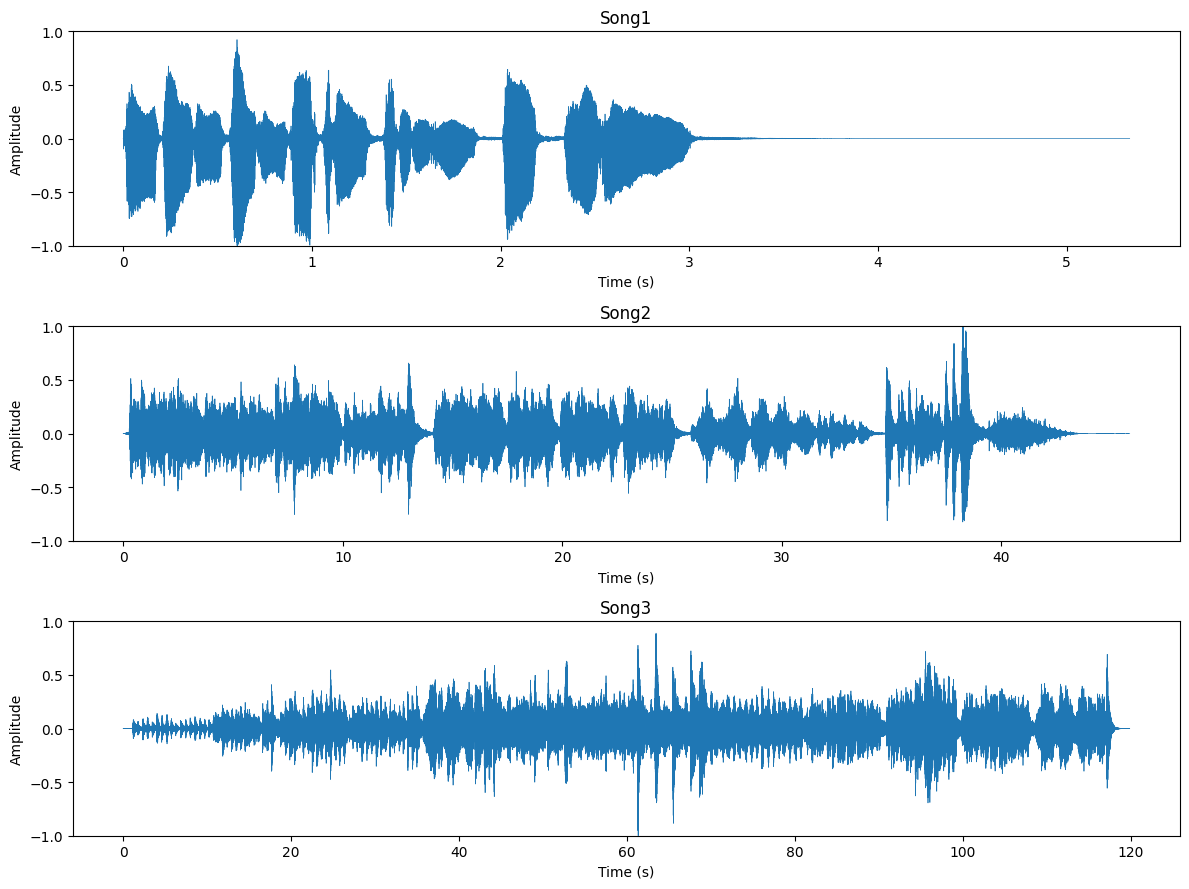

sample_count=512: window = 23 ms, frequency resolution = 43.1 Hz, time between columns = 5.8 ms
sample_count=2048: window = 93 ms, frequency resolution = 10.8 Hz, time between columns = 23.2 ms
sample_count=4096: window = 186 ms, frequency resolution = 5.4 Hz, time between columns = 46.4 ms


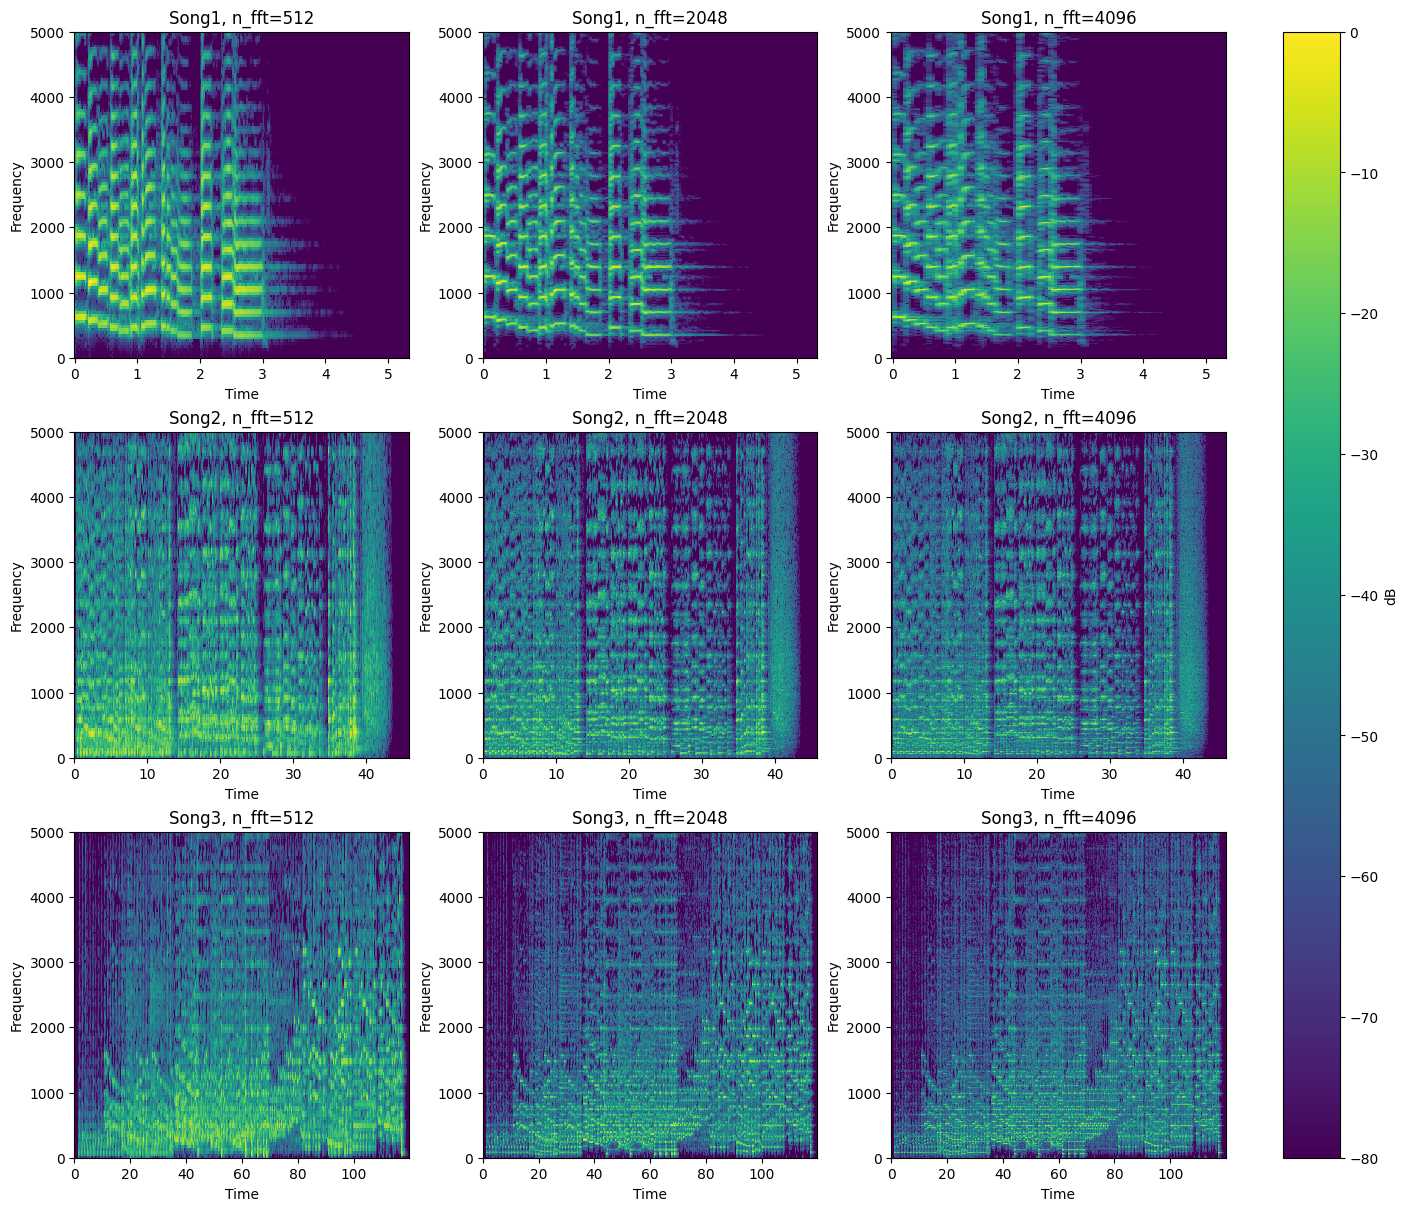

Song1: 92 peaks detected
Song2: 1346 peaks detected
Song3: 2395 peaks detected


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


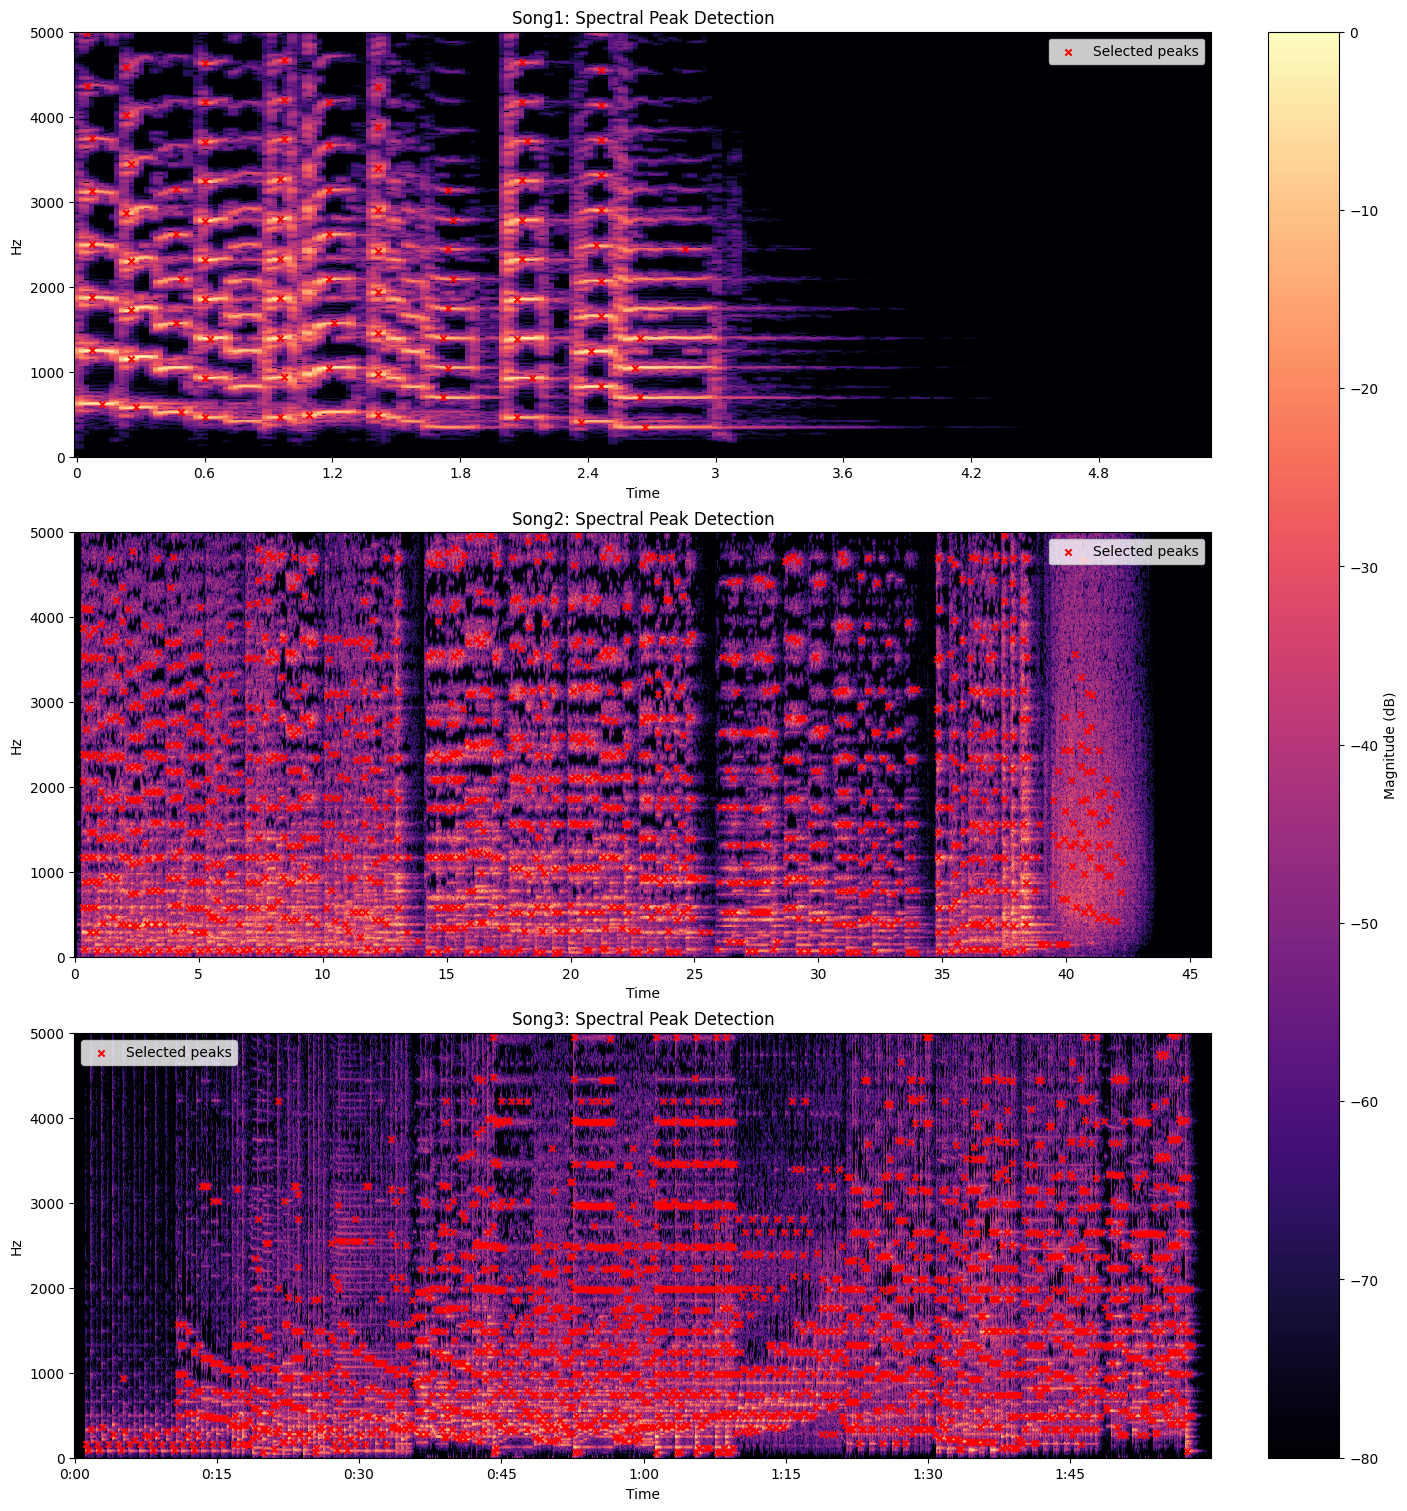


Threshold = -50 dB
Song1: 105 peaks
Song2: 1673 peaks
Song3: 4145 peaks

Threshold = -35 dB
Song1: 92 peaks
Song2: 1346 peaks
Song3: 2395 peaks

Threshold = -20 dB
Song1: 67 peaks
Song2: 507 peaks
Song3: 1095 peaks

Frequency spacing = 100 Hz, time spacing = 0.05 seconds
Song1: 154 peaks
Song2: 3114 peaks
Song3: 5742 peaks

Frequency spacing = 200 Hz, time spacing = 0.1 seconds
Song1: 92 peaks
Song2: 1346 peaks
Song3: 2395 peaks

Frequency spacing = 400 Hz, time spacing = 0.2 seconds
Song1: 46 peaks
Song2: 425 peaks
Song3: 922 peaks


In [ ]:
import numpy as np
import librosa
import matplotlib.pyplot as plt

t_srate = 22050

paths = {
    "Song1": librosa.ex('trumpet'),
    "Song2": librosa.ex('brahms'),
    "Song3": librosa.ex('nutcracker')
}

def inspect(path):
  y ,srate = librosa.load(path,sr=None,mono=False)
  #mono = False retains the og file's multi channel data and sr=None also preserves the og audio's srate

  dur = librosa.get_duration(y=y,sr = srate)
  # dur = y.shape[-1]/srate also works as shape[-1] gives the number of samples which when divided by srate gives the duration

  channels = y.shape[0] if y.ndim > 1 else 1
  #y has two dimensions if the file is stereo (channlels, samples) & one if the audio is mono the ifelse condition is for if the file is mono then shape[0]
  #gives the sample which is in the millions which will give deceptive results


  return srate,channels,dur

def load(path,target_srate = t_srate , normalize = True):
  y,srate = librosa.load(path,sr=None,mono=False)

  if y.ndim > 1 :
    # mostly efficiency nothing else as each step which uses y_mono now only handles a 1D structure and needs to compute less.(can skip)
    y_mono = librosa.to_mono(y)
  else:
    y_mono = y

  if srate!=target_srate:
    #resample takes in the audio file and changes the sampling rate, we set the target at 22050 Hz for uniformity across code
    y_resampled = librosa.resample(y_mono,orig_sr=srate,target_sr=target_srate)
  else:
    y_resampled = y_mono
  if normalize:
    peak = np.max(np.abs(y_resampled))
    if peak>0:
      y_resampled = y_resampled/peak
      #just to normalise the audio so that the loudest sample is exacly at height 1, improves consistency and also doesn't change the overall audio as each sample is multiplied by the same factor

  return y_resampled,target_srate
songs = {}
for name,path in paths.items():
  srate,channels,dur  = inspect(path)
  print(f"{srate},{channels},{dur}")
  y,sr = load(path)
  songs[name] = (y,sr)

#this creates a blankspace where we can plot the graph
fig, axes = plt.subplots(len(songs), 1, figsize=(12, 3 * len(songs)))

#ax(ax is the commonly used term, like how we use name use head pointer for linked lists) represents a plot area,(for 3 plots) it is the top most area for the first iteration, middle for the second and bottom for the third
#for each iteration the plot area has its own axes named t and y,here (t is basically the time axis, y is the audio data)
for ax, (name, (y, sr)) in zip(axes, songs.items()):
    # time axis: sample index divided by samples per second gives seconds
    t = np.arange((y.shape[0])) / sr
    ax.plot(t, y, linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    #we do a y limit to fix a vertical scale so that song peaks can directly be compared
    ax.set_ylim(-1, 1)

plt.tight_layout()
plt.show()

#Group 1 Task 2


#sample_count is basically the no. of samples in a window(basically a slice of the audio data) and hop_length basically describes the distance between the starting of windows
#we keep the windows overlapping to prevent losses, as end to end joining may cause some discrepancies
def comp_spectrogram(y, sample_count= 2048,hop_length= 512):

  #this is basically a way to perform stft(short-time fourier transform) in python to convert a signal from time domain to complex time-frequency domain, y_stft will basically be a complex-valued matrix
  y_stft = librosa.stft(y,n_fft=sample_count,hop_length=hop_length)

  #just keeping each frequency's strength and throwing away the phase
  y_mag = np.abs(y_stft)

  # we use the max as the ref, hence the max value is set to be 0, this makes the quiet details visible
  y_db = librosa.amplitude_to_db(y_mag, ref = np.max)

  return y_db

def plot_spectrogram(y,srate, sample_count,hop_length,ax,max_freq = 5000):

  #converts the frames to tims
  time = librosa.frames_to_time(np.arange(y.shape[1]),sr = srate,hop_length=hop_length)

  #returns the frequency of each row
  freq = librosa.fft_frequencies(sr=srate,n_fft=sample_count)

  #draws each cell as a rectangle positioned by time and freq , the shading = "auto" selects the optimal shadin mode to be used, it's like how we used loc='best' when making a legend in matplotlib
  spectrogram = ax.pcolormesh(time,freq,y,shading = "auto")


  ax.set_ylim(0,max_freq)
  ax.set_xlabel("Time")
  ax.set_ylabel("Frequency")

  return spectrogram


#this below shows the number associated with different samples per window
for sample_count in [512, 2048, 4096]:
    hop = sample_count // 4
    print(f"sample_count={sample_count}: window = {1000 * sample_count / t_srate:.0f} ms, "
          f"frequency resolution = {t_srate / sample_count:.1f} Hz, "
          f"time between columns = {1000 * hop / t_srate:.1f} ms")

window_sizes = [512, 2048,4096]
#added the constrained_layout as the color_bar was clipping inside the graphs
fig, axes = plt.subplots(len(songs), len(window_sizes), figsize=(14, 4 * len(songs)),constrained_layout=True)



for i, (name, (y, sr)) in enumerate(songs.items()):
    for j, n in enumerate(window_sizes):
        hop = n // 4   # same 75% overlap, so only the window size changes
        y_db = comp_spectrogram(y, n, hop)
        img = plot_spectrogram(y_db, sr, n, hop, axes[i, j])
        axes[i, j].set_title(f"{name}, n_fft={n}")

fig.colorbar(img, ax=axes, label="dB")
plt.show()

#i personally think 2048 looks the best with low smearing and stretchiness, the smearing is slightly more apparent with 512 and 4096 looks very sparse
#I think 2048 is a nice middle ground
SAMPLE_COUNT, HOP_LENGTH = 2048,512

specs = {name: comp_spectrogram(y, SAMPLE_COUNT, HOP_LENGTH) for name, (y, sr) in songs.items()}
#GROUP 1 - TASK 2 ENDS

# GROUP 1 - TASK 3: SPECTRAL PEAK DETECTION


from scipy.ndimage import maximum_filter


def detect_peaks(y_db, sr, sample_count=2048, hop_length=512,
                 threshold_db=-35, min_freq_spacing=200,
                 min_time_spacing=0.1, max_freq=5000):
    """
    Detect prominent local maxima in a decibel spectrogram.

    Parameters
    ----------
    y_db : 2D NumPy array
        Spectrogram expressed in decibels.
    sr : int
        Audio sample rate in samples per second.
    sample_count : int
        FFT size used to calculate the spectrogram.
    hop_length : int
        Number of audio samples between consecutive frames.
    threshold_db : float
        Minimum dB value required for a candidate peak.
    min_freq_spacing : float
        Minimum desired spacing in frequency, in Hz.
    min_time_spacing : float
        Minimum desired spacing in time, in seconds.
    max_freq : float
        Highest frequency to analyse, in Hz.

    Returns
    -------
    peak_times : NumPy array
        Times of selected peaks, in seconds.
    peak_freqs : NumPy array
        Frequencies of selected peaks, in Hz.
    """

    # Adjacent FFT frequency bins are separated by sr / sample_count Hz.
    freq_resolution = sr / sample_count

    # Adjacent spectrogram frames are separated by hop_length / sr seconds.
    time_resolution = hop_length / sr

    # Array indices must be whole numbers, so round to the nearest bin.
    freq_gap = max(1, int(round(min_freq_spacing / freq_resolution)))
    time_gap = max(1, int(round(min_time_spacing / time_resolution)))

    # This focuses detection on the frequency range we want to analyse.
    max_bin = min(int(max_freq / freq_resolution), y_db.shape[0] - 1)
    S = y_db[:max_bin + 1, :]

    # The neighbourhood extends in both frequency and time.
    # A local maximum has the same value as this filtered result.
    local_max = maximum_filter(
        S,
        size=(2 * freq_gap + 1, 2 * time_gap + 1),
        mode="constant",
        cval=-np.inf
    )

    # A point must be a local maximum AND reach the dB threshold.
    is_peak = (S == local_max) & (S >= threshold_db)

    # Get the row (frequency-bin) and column (time-frame) of each candidate.
    rows, cols = np.where(is_peak)

    # We accept strong peaks first, so weaker nearby candidates can be removed.
    strengths = S[rows, cols]
    order = np.argsort(strengths)[::-1]

    # Each accepted peak is stored as (frequency-bin index, time-frame index).
    selected = []

    for i in order:
        f = rows[i]  # Candidate frequency-bin index
        t = cols[i]  # Candidate time-frame index

        # Assume this candidate is far enough from all selected peaks.
        too_close = False

        # Compare the candidate with every peak already selected.
        for old_f, old_t in selected:

            # Reject it if it is too close in BOTH frequency and time
            # to an already selected peak.
            if (abs(f - old_f) < freq_gap and
                    abs(t - old_t) < time_gap):
                too_close = True
                break

        # Keep the candidate only if it passed the spacing check.
        if not too_close:
            selected.append((f, t))

    # reshape(-1, 2) also works when no peaks were selected.
    selected = np.array(selected, dtype=int).reshape(-1, 2)

    #Convert frequency-bin indices into Hz.
    peak_freqs = selected[:, 0] * freq_resolution

    # Convert time-frame indices into seconds using Librosa.
    peak_times = librosa.frames_to_time(
        selected[:, 1],
        sr=sr,
        hop_length=hop_length
    )

    # Return peak coordinates for plotting or later fingerprinting.
    return peak_times, peak_freqs

# Store the results so we do not need to detect the peaks again for plotting.
peak_results = {}

# Process each song using its already-computed Task 2 spectrogram.
for name, (y, sr) in songs.items():

    # Retrieve this song's spectrogram from Task 2.
    # It should be in decibels for thresholds such as -35 dB to make sense.
    y_db = specs[name]

    # Detect peaks using our initial settings.
    peak_times, peak_freqs = detect_peaks(
        y_db,
        sr,
        sample_count=SAMPLE_COUNT,
        hop_length=HOP_LENGTH,
        threshold_db=-35,
        min_freq_spacing=200,
        min_time_spacing=0.1,
        max_freq=5000
    )

    # Save times and frequencies under the song's name.
    peak_results[name] = (peak_times, peak_freqs)

    # Display the number of peaks found for this song.
    print(f"{name}: {len(peak_times)} peaks detected")

# Make one subplot per song, with enough height for clear inspection.
fig, axes = plt.subplots(
    len(songs), 1,
    figsize=(14, 5 * len(songs)),
    constrained_layout=True
)

# Ensure axes is an array even if only one song is present.
axes = np.atleast_1d(axes)

# Pair each song with one of the subplot axes.
for ax, (name, (y, sr)) in zip(axes, songs.items()):

    # Plot the spectrogram from Task 2.
    # x_axis='time' labels the horizontal axis in seconds.
    # y_axis='hz' labels the vertical axis in Hertz.
    img = librosa.display.specshow(
        specs[name],
        sr=sr,
        hop_length=HOP_LENGTH,
        n_fft=SAMPLE_COUNT,
        x_axis="time",
        y_axis="hz",
        ax=ax
    )

    # Retrieve the peaks already detected for this song.
    peak_times, peak_freqs = peak_results[name]

    # Overlay red crosses at the selected peak coordinates.
    # Each cross marks one detected local maximum.
    ax.scatter(
        peak_times,
        peak_freqs,
        color="red",
        marker="x",
        s=20,
        label="Selected peaks"
    )

    # Add a title, restrict the visible frequency range, and show the legend.
    ax.set_title(f"{name}: Spectral Peak Detection")
    ax.set_ylim(0, 5000)
    ax.legend()

# Add a colour bar showing the spectrogram magnitude in dB.
fig.colorbar(img, ax=axes, label="Magnitude (dB)")
plt.show()

# A lower threshold (e.g. -50 dB) usually allows more weak peaks.
# A higher threshold (e.g. -20 dB) usually keeps only stronger peaks.
thresholds = [-50, -35, -20]

for threshold in thresholds:
    print(f"\nThreshold = {threshold} dB")

    # Test the same threshold on each song.
    for name, (y, sr) in songs.items():
        times, freqs = detect_peaks(
            specs[name],
            sr,
            sample_count=SAMPLE_COUNT,
            hop_length=HOP_LENGTH,
            threshold_db=threshold,
            min_freq_spacing=200,
            min_time_spacing=0.1,
            max_freq=5000
        )

        # The count makes it easy to compare settings quantitatively.
        print(f"{name}: {len(times)} peaks")

# Each tuple contains (frequency spacing in Hz, time spacing in seconds).
# Larger spacing generally removes more closely spaced peaks.
spacing_settings = [
    (100, 0.05),  # Small spacing
    (200, 0.10),  # Moderate spacing
    (400, 0.20)   # Large spacing
]

for freq_gap, time_gap in spacing_settings:
    print(
        f"\nFrequency spacing = {freq_gap} Hz, "
        f"time spacing = {time_gap} seconds"
    )

    # Compare this spacing setting across all songs.
    for name, (y, sr) in songs.items():
        times, freqs = detect_peaks(
            specs[name],
            sr,
            sample_count=SAMPLE_COUNT,
            hop_length=HOP_LENGTH,
            threshold_db=-35,
            min_freq_spacing=freq_gap,
            min_time_spacing=time_gap,
            max_freq=5000
        )

        print(f"{name}: {len(times)} peaks")

# END OF TASK 3


Song1: 1260 peak-pair fingerprints generated
Song2: 20070 peak-pair fingerprints generated
Song3: 35583 peak-pair fingerprints generated


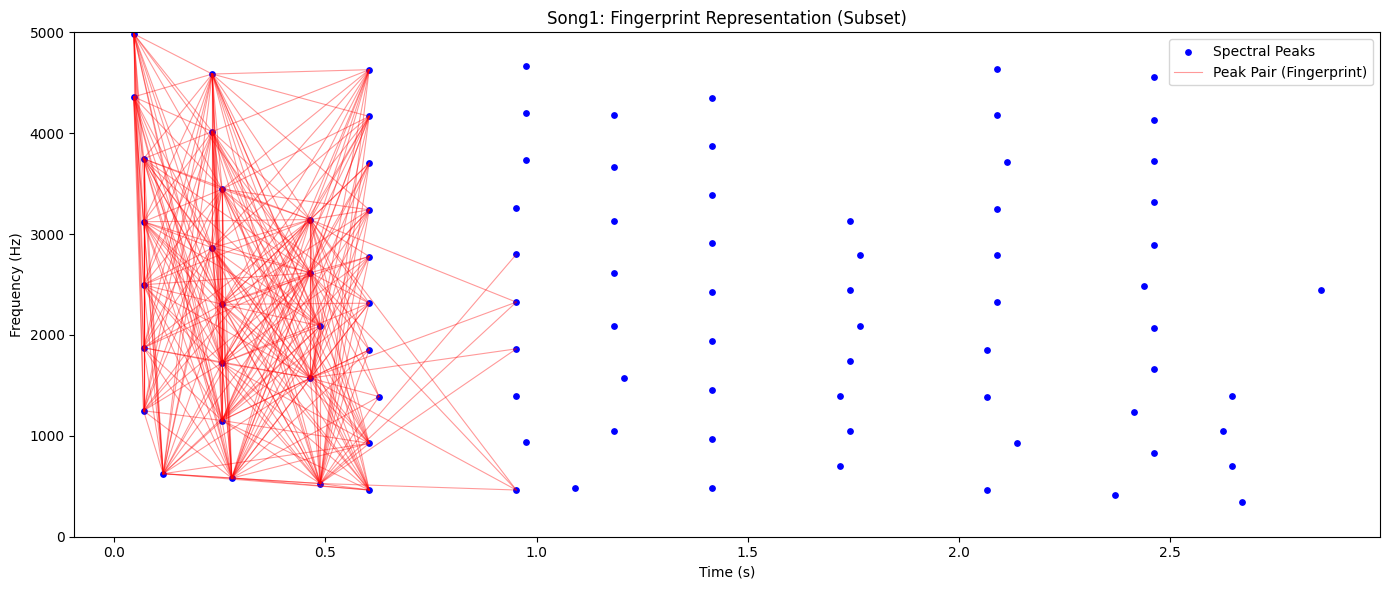

In [ ]:

# GROUP 2 - TASK 4: FINGERPRINT REPRESENTATION

import numpy as np
import matplotlib.pyplot as plt

def generate_fingerprints(peak_times, peak_freqs, fan_out=15, min_time_delta=0.0, max_time_delta=2.0):
    """
    Generate peak-pair fingerprints from a list of peak times and frequencies.

    Parameters
    ----------
    peak_times : NumPy array of peak times in seconds.
    peak_freqs : NumPy array of peak frequencies in Hz.
    fan_out : int, number of adjacent peaks to pair with each anchor peak.
    min_time_delta : float, minimum time separation for a valid pair.
    max_time_delta : float, maximum time separation for a valid pair.

    Returns
    -------
    fingerprints : list of dictionaries containing peak pair data.
    """
    # Sort peaks chronologically to easily define the forward "target zone"
    sort_idx = np.argsort(peak_times)
    t_sorted = peak_times[sort_idx]
    f_sorted = peak_freqs[sort_idx]

    fingerprints = []

    # Iterate over each peak to act as an "anchor" point
    for i in range(len(t_sorted)):
        anchor_t = t_sorted[i]
        anchor_f = f_sorted[i]

        # Look ahead at the next few peaks bounded by the fan_out limit
        for j in range(i + 1, min(i + 1 + fan_out, len(t_sorted))):
            target_t = t_sorted[j]
            target_f = f_sorted[j]

            delta_t = target_t - anchor_t

            # Record the pair if the time separation is within our desired window
            if min_time_delta <= delta_t <= max_time_delta:
                fingerprints.append({
                    'f1': anchor_f,
                    'f2': target_f,
                    'delta_t': delta_t,
                    't1': anchor_t, # Saved for visualization purposes
                    't2': target_t  # Saved for visualization purposes
                })

    return fingerprints

# ------------------------------------------------------------
# PART A: GENERATE FINGERPRINTS FOR ALL SONGS
# ------------------------------------------------------------
fingerprint_results = {}

for name in songs.keys():
    # Retrieve the peak coordinates detected in Task 3
    ptimes, pfreqs = peak_results[name]

    # Generate the peak pairs
    fps = generate_fingerprints(ptimes, pfreqs, fan_out=15)
    fingerprint_results[name] = fps

    print(f"{name}: {len(fps)} peak-pair fingerprints generated")

# PART B: VISUALISE THE FINGERPRINTS

# We'll plot the fingerprints for the first song.
# We restrict the plot to a subset of pairs so the graph isn't too cluttered.
sample_song = list(songs.keys())[0]
sample_fps = fingerprint_results[sample_song]

fig, ax = plt.subplots(figsize=(14, 6))

# Plot the original peaks
ptimes, pfreqs = peak_results[sample_song]
ax.scatter(ptimes, pfreqs, color='blue', marker='o', s=15, label="Spectral Peaks")

# Draw lines connecting the anchor and target peaks (our fingerprints)
# Plotting just a 300-pair subset to keep the visualization clear
subset_fps = sample_fps[:300]

for idx, fp in enumerate(subset_fps):
    # Only add the label to the first line to avoid legend duplication
    label = "Peak Pair (Fingerprint)" if idx == 0 else None
    ax.plot([fp['t1'], fp['t2']], [fp['f1'], fp['f2']],
            color='red', alpha=0.4, linewidth=0.8, label=label)

ax.set_title(f"{sample_song}: Fingerprint Representation (Subset)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Frequency (Hz)")
ax.set_ylim(0, 5000)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()
#TASK 4 ENDS

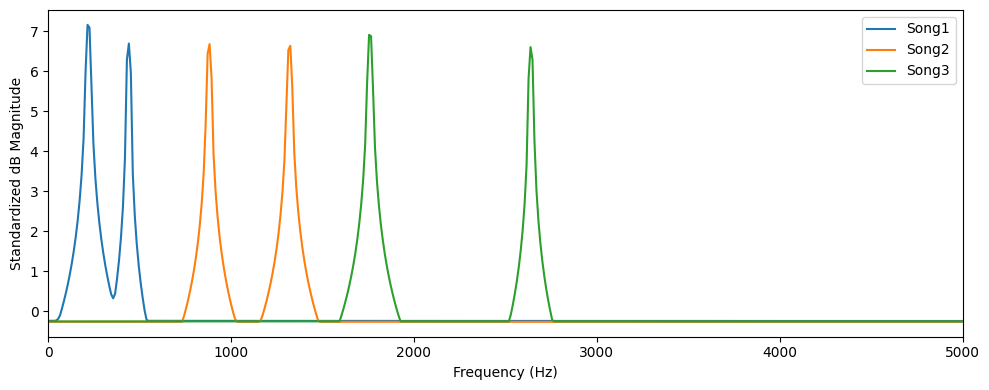

In [77]:
#TASK 5 BEGINS
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

TARGET_SRATE = 22050
SAMPLE_COUNT = 2048
HOP_LENGTH = 512

paths = {
    "Song1": "/content/Achachak - First Movement.mp3",
    "Song2": "/content/Joint C Beat Laboratory - Margo.mp3",
    "Song3": "/content/Joint C Beat Laboratory - Nerves.mp3"
}

def load_audio(path, target_srate=TARGET_SRATE, normalize=True):
    y, srate = librosa.load(path, sr=None, mono=False)
    y_mono = librosa.to_mono(y) if y.ndim > 1 else y
    if srate != target_srate:
        y_resampled = librosa.resample(y_mono, orig_sr=srate, target_sr=target_srate)
    else:
        y_resampled = y_mono
    if normalize:
        peak = np.max(np.abs(y_resampled))
        if peak > 0:
            y_resampled = y_resampled / peak
    return y_resampled, target_srate

def comp_spectrogram(y, sample_count=SAMPLE_COUNT, hop_length=HOP_LENGTH):
    y_stft = librosa.stft(y, n_fft=sample_count, hop_length=hop_length)
    y_mag = np.abs(y_stft)
    return librosa.amplitude_to_db(y_mag, ref=np.max)
def extract_average_spectral_features(y, sr=TARGET_SRATE, sample_count=SAMPLE_COUNT,
                                      hop_length=HOP_LENGTH, max_freq=5000, include_std=False):
    stft_matrix = np.abs(librosa.stft(y, n_fft=sample_count, hop_length=hop_length))
    db_spec = librosa.amplitude_to_db(stft_matrix, ref=np.max)
    freq_resolution = sr / sample_count
    max_bin = min(int(max_freq / freq_resolution), db_spec.shape[0] - 1)
    db_spec_filtered = db_spec[:max_bin + 1, :]
    freq_axis = librosa.fft_frequencies(sr=sr, n_fft=sample_count)[:max_bin + 1]
    mean_spectrum = np.mean(db_spec_filtered, axis=1)
    mean_spectrum = (mean_spectrum - np.mean(mean_spectrum)) / (np.std(mean_spectrum) + 1e-8)
    if include_std:
        std_spectrum = np.std(db_spec_filtered, axis=1)
        std_spectrum = (std_spectrum - np.mean(std_spectrum)) / (np.std(std_spectrum) + 1e-8)
        feature_vector = np.concatenate([mean_spectrum, std_spectrum])
    else:
        feature_vector = mean_spectrum
    return feature_vector, freq_axis

def compute_similarity(feat_query, feat_target, metric="cosine"):
    u = np.asarray(feat_query, dtype=float)
    v = np.asarray(feat_target, dtype=float)
    if metric == "cosine":
        norm_u = np.linalg.norm(u)
        norm_v = np.linalg.norm(v)
        return float(np.dot(u, v) / (norm_u * norm_v)) if (norm_u > 0 and norm_v > 0) else 0.0
    elif metric == "correlation":
        u_c = u - np.mean(u)
        v_c = v - np.mean(v)
        norm_u = np.linalg.norm(u_c)
        norm_v = np.linalg.norm(v_c)
        return float(np.dot(u_c, v_c) / (norm_u * norm_v)) if (norm_u > 0 and norm_v > 0) else 0.0
    elif metric == "euclidean":
        dist = np.linalg.norm(u - v)
        return float(1.0 / (1.0 + dist))
    else:
        raise ValueError(f"Unknown metric '{metric}'")
class BaselineSpectralRecogniser:
    def __init__(self, sample_count=SAMPLE_COUNT, hop_length=HOP_LENGTH,
                 max_freq=5000, metric="cosine", include_std=False):
        self.sample_count = sample_count
        self.hop_length = hop_length
        self.max_freq = max_freq
        self.metric = metric
        self.include_std = include_std
        self.database = {}
        self.freq_axis = None

    def index_song(self, name, y, sr=TARGET_SRATE):
        features, freq_axis = extract_average_spectral_features(
            y, sr=sr, sample_count=self.sample_count, hop_length=self.hop_length,
            max_freq=self.max_freq, include_std=self.include_std
        )
        self.database[name] = {"features": features, "raw_audio": y, "sr": sr}
        self.freq_axis = freq_axis

    def recognize(self, query_y, sr=TARGET_SRATE):
        if not self.database:
            raise ValueError("Database is empty! Call index_song() first.")
        query_feat, _ = extract_average_spectral_features(
            query_y, sr=sr, sample_count=self.sample_count, hop_length=self.hop_length,
            max_freq=self.max_freq, include_std=self.include_std
        )
        scores = {}
        for name, data in self.database.items():
            scores[name] = compute_similarity(query_feat, data["features"], metric=self.metric)
        ranked_results = sorted(scores.items(), key=lambda item: item[1], reverse=True)
        return ranked_results[0][0], ranked_results[0][1], ranked_results

def identify_query_clip(query_audio, songs_dict, metric="cosine"):
    recogniser = BaselineSpectralRecogniser(metric=metric)
    for name, (y, sr) in songs_dict.items():
        recogniser.index_song(name, y, sr)
    best_song, best_score, _ = recogniser.recognize(query_audio)
    return best_song, best_score

def extract_query_clip(y, sr, start_sec, duration_sec, noise_snr_db=None, gain=1.0):
    start_sample = int(start_sec * sr)
    end_sample = start_sample + int(duration_sec * sr)
    clip = y[start_sample:min(end_sample, len(y))].copy() * gain
    if noise_snr_db is not None:
        signal_power = np.mean(clip ** 2)
        noise_power = signal_power / (10 ** (noise_snr_db / 10))
        noise = np.random.normal(0, np.sqrt(max(noise_power, 1e-12)), len(clip))
        clip = clip + noise
    return clip
songs = {}
for name, path in paths.items():
    if os.path.exists(path):
        y, sr = load_audio(path)
        songs[name] = (y, sr)
    else:
        duration = 60.0
        t = np.linspace(0, duration, int(TARGET_SRATE * duration), endpoint=False)
        if name == "Song1":
            y = 0.6 * np.sin(2 * np.pi * 220 * t) + 0.3 * np.sin(2 * np.pi * 440 * t)
        elif name == "Song2":
            y = 0.4 * np.sin(2 * np.pi * 880 * t) + 0.4 * np.sin(2 * np.pi * 1320 * t)
        else:
            y = 0.5 * np.sin(2 * np.pi * 1760 * t) + 0.3 * np.sin(2 * np.pi * 2640 * t)
        y = y / np.max(np.abs(y))
        songs[name] = (y, TARGET_SRATE)

recogniser = BaselineSpectralRecogniser(metric="cosine")
for name, (y, sr) in songs.items():
    recogniser.index_song(name, y, sr)

plt.figure(figsize=(10, 4))
for name, data in recogniser.database.items():
    plt.plot(recogniser.freq_axis, data["features"], label=name)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Standardized dB Magnitude")
plt.xlim(0, 5000)
plt.legend()
plt.tight_layout()
plt.show()

In [78]:
test_configs = [
    ("Song1", 15.0, 10.0),
    ("Song2", 25.0, 10.0),
    ("Song3", 35.0, 10.0)
]

for true_song, start_sec, duration_sec in test_configs:
    y_full, sr = songs[true_song]
    query_clip = extract_query_clip(y_full, sr, start_sec, duration_sec)
    pred_song, best_score, leaderboard = recogniser.recognize(query_clip, sr=sr)
    print(f"Query: {true_song} [{start_sec}s-{start_sec+duration_sec}s] -> Predicted: {pred_song} (Score: {best_score:.4f})")
    for rank, (name, score) in enumerate(leaderboard, start=1):
        print(f"   {rank}. {name}: {score:.5f}")

Query: Song1 [15.0s-25.0s] -> Predicted: Song1 (Score: 1.0000)
   1. Song1: 0.99997
   2. Song2: -0.06375
   3. Song3: -0.06421
Query: Song2 [25.0s-35.0s] -> Predicted: Song2 (Score: 1.0000)
   1. Song2: 0.99998
   2. Song1: -0.06364
   3. Song3: -0.06886
Query: Song3 [35.0s-45.0s] -> Predicted: Song3 (Score: 1.0000)
   1. Song3: 0.99999
   2. Song1: -0.06383
   3. Song2: -0.06853


In [79]:
def sliding_window_recogniser(query_y, songs_dict, chunk_duration_sec=10.0, step_sec=2.0, sr=TARGET_SRATE):
    query_feat, _ = extract_average_spectral_features(query_y, sr=sr)
    results = {}
    best_offsets = {}
    chunk_samples = int(chunk_duration_sec * sr)
    step_samples = int(step_sec * sr)
    for name, (song_y, song_sr) in songs_dict.items():
        max_sim = -1.0
        best_time = 0.0
        for start in range(0, len(song_y) - chunk_samples, step_samples):
            chunk = song_y[start:start + chunk_samples]
            chunk_feat, _ = extract_average_spectral_features(chunk, sr=song_sr)
            sim = compute_similarity(query_feat, chunk_feat, metric="cosine")
            if sim > max_sim:
                max_sim = sim
                best_time = start / sr
        results[name] = max_sim
        best_offsets[name] = best_time
    sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
    return sorted_results[0][0], sorted_results[0][1], best_offsets[sorted_results[0][0]], sorted_results

query_test = extract_query_clip(songs["Song2"][0], TARGET_SRATE, 40.0, 10.0)
best_s, best_sc, est_time, ranked = sliding_window_recogniser(query_test, songs, chunk_duration_sec=10.0)
print(f"Sliding Window Top Match: {best_s} | Score: {best_sc:.4f} | Estimated Offset: {est_time:.1f}s")
for rank, (s_name, s_score) in enumerate(ranked, 1):
    print(f"  {rank}. {s_name}: {s_score:.4f}")
    #TASK 5 ENDS

Sliding Window Top Match: Song2 | Score: 1.0000 | Estimated Offset: 0.0s
  1. Song2: 1.0000
  2. Song1: -0.0616
  3. Song3: -0.0678


In [ ]:
#TASK 6 BEGINS
import numpy as np
import scipy.ndimage as ndimage
import librosa
import matplotlib.pyplot as plt
from collections import defaultdict

# 1. DSP & AUDIO CONFIGURATION PARAMETERS (Consistent with Tasks 1, 2 & 5)

TARGET_SRATE = 22050        # Sampling rate in Hz
SAMPLE_COUNT = 2048        # FFT window size (N_FFT)
HOP_LENGTH = 512           # Hop length in samples (75% overlap)
MAX_FREQ = 5000            # Upper frequency bound in Hz
MIN_FREQ = 80              # Lower frequency bound to ignore DC / hum

# Peak detection parameters
PEAK_NEIGHBORHOOD_FREQ = 10  # Minimum frequency separation in bins (~108 Hz)
PEAK_NEIGHBORHOOD_TIME = 10  # Minimum time separation in frames (~232 ms)
AMP_THRESHOLD_DB = -40.0     # Minimum decibel magnitude for peak candidate

# Combinatorial peak-pairing parameters (Shazam Target Zone)
TARGET_ZONE_T_MIN = 2       # Minimum forward time offset (~46 ms)
TARGET_ZONE_T_MAX = 50      # Maximum forward time offset (~1.16 s)
TARGET_ZONE_F_MAX = 80      # Maximum frequency difference in bins (~860 Hz)
FAN_OUT = 7                 # Max target peaks paired with each anchor peak

# 2. AUDIO LOADING & SPECTROGRAM GENERATION

def load_audio(path, target_srate=TARGET_SRATE, normalize=True):
    """
    Loads an audio file, converts it to mono, resamples to target_srate,
    and normalizes peak amplitude to 1.0.
    """
    y, srate = librosa.load(path, sr=None, mono=False)
    y_mono = librosa.to_mono(y) if y.ndim > 1 else y
    if srate != target_srate:
        y_resampled = librosa.resample(y_mono, orig_sr=srate, target_sr=target_srate)
    else:
        y_resampled = y_mono
    if normalize:
        peak = np.max(np.abs(y_resampled))
        if peak > 0:
            y_resampled = y_resampled / peak
    return y_resampled, target_srate

def comp_spectrogram(y, sample_count=SAMPLE_COUNT, hop_length=HOP_LENGTH):
    """
    Computes a decibel magnitude spectrogram using Short-Time Fourier Transform.
    """
    y_stft = librosa.stft(y, n_fft=sample_count, hop_length=hop_length)
    y_mag = np.abs(y_stft)
    # AMENDED BY GROUP 3: top_db=None added.
    # By default amplitude_to_db flattens everything more than 80 dB below the clip's loudest point
    # to ONE identical value. For loud clips that flat floor lies above AMP_THRESHOLD_DB (-40 dB), and
    # find_spectral_peaks then counted every cell of a quiet passage as a "peak" (all cells of a flat
    # region equal their neighbourhood maximum). Those fake peaks produced tens of thousands of repeated
    # hashes and inflated the votes. With top_db=None quiet cells keep their true (very low) values,
    # stay below the threshold, and only real peaks remain. Checked in the cell after the Task 6 test.
    return librosa.amplitude_to_db(y_mag, ref=1.0, top_db=None)

# 3. SPECTRAL PEAK DETECTION (CONSTELLATION MAP)

def find_spectral_peaks(spec_db,
                        neighborhood_freq=PEAK_NEIGHBORHOOD_FREQ,
                        neighborhood_time=PEAK_NEIGHBORHOOD_TIME,
                        amp_threshold_db=AMP_THRESHOLD_DB,
                        min_freq=MIN_FREQ,
                        max_freq=MAX_FREQ,
                        sr=TARGET_SRATE,
                        sample_count=SAMPLE_COUNT):
    '''
    Extracts prominent local maxima from a decibel spectrogram.
    Uses a 2D maximum filter to suppress non-maximal points within
    (2*freq + 1, 2*time + 1) bins.

    Returns:
        peaks: List of tuples (freq_bin, time_frame, amp_db) sorted by time_frame.
    '''
    # Restrict to meaningful frequency bounds
    freq_resolution = sr / sample_count
    min_bin = max(0, int(min_freq / freq_resolution))
    max_bin = min(int(max_freq / freq_resolution), spec_db.shape[0] - 1)

    bounded_spec = spec_db[min_bin:max_bin + 1, :]
    filter_size = (2 * neighborhood_freq + 1, 2 * neighborhood_time + 1)
    local_max = ndimage.maximum_filter(bounded_spec, size=filter_size)

    # A cell is a peak if it equals the neighborhood maximum and exceeds the threshold
    is_peak = (bounded_spec == local_max) & (bounded_spec >= amp_threshold_db)

    peak_freq_indices, peak_time_indices = np.where(is_peak)

    # Map frequency indices back to original spectrogram coordinates
    peaks = []
    for f_idx, t_idx in zip(peak_freq_indices, peak_time_indices):
        orig_f_bin = f_idx + min_bin
        amp = spec_db[orig_f_bin, t_idx]
        peaks.append((orig_f_bin, int(t_idx), float(amp)))

    # Sort peaks by time frame, then frequency bin
    peaks.sort(key=lambda p: (p[1], p[0]))
    return peaks

# 4. COMBINATORIAL PEAK-PAIRING & HASH GENERATION (WANG 2003)

def generate_peak_pair_hashes(peaks,
                              target_zone_t_min=TARGET_ZONE_T_MIN,
                              target_zone_t_max=TARGET_ZONE_T_MAX,
                              target_zone_f_max=TARGET_ZONE_F_MAX,
                              fan_out=FAN_OUT):
    """
    Forms pairs of spectral peaks following Avery Wang's Shazam algorithm.
    For each anchor peak (f1, t1), searches a forward target zone for up to
    fan_out target peaks (f2, t2) where:
        t1 + target_zone_t_min <= t2 <= t1 + target_zone_t_max
        |f2 - f1| <= target_zone_f_max

    Hash key format:
        (f1, f2, delta_t) represented as an integer: (f1 << 20) | (f2 << 8) | delta_t
        or as a tuple (f1, f2, delta_t).

    Returns:
        fingerprints: List of (hash_key, t1_anchor_frame)
    """
    fingerprints = []
    n_peaks = len(peaks)

    for i in range(n_peaks):
        f1, t1, _ = peaks[i]
        targets_paired = 0

        for j in range(i + 1, n_peaks):
            f2, t2, _ = peaks[j]
            delta_t = t2 - t1

            if delta_t < target_zone_t_min:
                continue
            if delta_t > target_zone_t_max:
                break  # Since peaks are sorted chronologically, no future peak can satisfy this

            if abs(f2 - f1) <= target_zone_f_max:
                # Pack (f1, f2, delta_t) into a hash key
                # f1 (0-1024, ~10 bits), f2 (0-1024, ~10 bits), delta_t (0-255, ~8 bits)
                hash_key = (int(f1) << 20) | (int(f2) << 8) | int(delta_t)
                fingerprints.append((hash_key, t1))

                targets_paired += 1
                if targets_paired >= fan_out:
                    break

    return fingerprints

# 5. SHAZAM PEAK-PAIR RECOGNISER CLASS

class ShazamPeakPairRecogniser:
    '''
    Shazam-style audio recogniser utilizing combinatorial peak-pair matching
    
    '''
    def __init__(self,
                 sr=TARGET_SRATE,
                 sample_count=SAMPLE_COUNT,
                 hop_length=HOP_LENGTH,
                 neighborhood_freq=PEAK_NEIGHBORHOOD_FREQ,
                 neighborhood_time=PEAK_NEIGHBORHOOD_TIME,
                 amp_threshold_db=AMP_THRESHOLD_DB,
                 target_zone_t_min=TARGET_ZONE_T_MIN,
                 target_zone_t_max=TARGET_ZONE_T_MAX,
                 target_zone_f_max=TARGET_ZONE_F_MAX,
                 fan_out=FAN_OUT):
        self.sr = sr
        self.sample_count = sample_count
        self.hop_length = hop_length
        self.neighborhood_freq = neighborhood_freq
        self.neighborhood_time = neighborhood_time
        self.amp_threshold_db = amp_threshold_db
        self.target_zone_t_min = target_zone_t_min
        self.target_zone_t_max = target_zone_t_max
        self.target_zone_f_max = target_zone_f_max
        self.fan_out = fan_out

        # Inverted index: hash_key -> list of (song_name, anchor_frame)
        self.database = defaultdict(list)
        self.songs_info = {}

    def extract_fingerprints(self, y):
        '''
        Processes audio to extract STFT peaks and generates peak-pair hashes.
        Returns:
            fingerprints: List of (hash_key, anchor_frame)
            peaks: List of (f, t, amp)
            spec_db: Decibel spectrogram
        '''
        spec_db = comp_spectrogram(y, sample_count=self.sample_count, hop_length=self.hop_length)
        peaks = find_spectral_peaks(
            spec_db,
            neighborhood_freq=self.neighborhood_freq,
            neighborhood_time=self.neighborhood_time,
            amp_threshold_db=self.amp_threshold_db,
            sr=self.sr,
            sample_count=self.sample_count
        )
        fingerprints = generate_peak_pair_hashes(
            peaks,
            target_zone_t_min=self.target_zone_t_min,
            target_zone_t_max=self.target_zone_t_max,
            target_zone_f_max=self.target_zone_f_max,
            fan_out=self.fan_out
        )
        return fingerprints, peaks, spec_db

    def index_song(self, song_name, y):
        
        # Extracts fingerprints from audio and populates the inverted index.
        
        fingerprints, peaks, _ = self.extract_fingerprints(y)
        duration_sec = len(y) / self.sr

        for hash_key, anchor_t in fingerprints:
            self.database[hash_key].append((song_name, anchor_t))

        self.songs_info[song_name] = {
            "duration_sec": duration_sec,
            "num_peaks": len(peaks),
            "num_fingerprints": len(fingerprints)
        }

    def recognize(self, query_y):
        
        # Identifies the source song of an unknown query clip using offset voting.

        # Returns:
        #     predicted_song: Name of best matching song
        #     best_offset_sec: Estimated time in seconds where query starts in reference track
        #     best_score: Peak vote count at best offset
        #     offset_histograms: Dict mapping song_name -> (offsets_sec_array, vote_counts_array)
        #     leaderboard: Ranked list of (song_name, peak_votes, best_offset_sec, confidence_ratio)
        
        if not self.database:
            raise ValueError("Database is empty! Call index_song() before recognition.")

        query_fps, _, _ = self.extract_fingerprints(query_y)
        if not query_fps:
            raise ValueError("No spectral peaks detected in query clip; audio may be silent.")

        # Track offset votes: song_name -> {offset_frame: count}
        # offset_frame = song_anchor_t - query_anchor_t
        song_offset_votes = defaultdict(lambda: defaultdict(int))

        for q_hash, q_t in query_fps:
            matches = self.database.get(q_hash, None)
            if matches:
                for song_name, song_t in matches:
                    offset = song_t - q_t
                    song_offset_votes[song_name][offset] += 1

        leaderboard = []
        offset_histograms = {}

        # Evaluate each song in the database
        for song_name in self.songs_info.keys():
            votes_dict = song_offset_votes.get(song_name, {})
            if votes_dict:
                # Find maximum votes in any offset bin
                best_offset_frame, peak_votes = max(votes_dict.items(), key=lambda x: x[1])
                best_offset_sec = best_offset_frame * (self.hop_length / self.sr)

                # Convert votes_dict to sorted numpy arrays for histogram plotting
                sorted_items = sorted(votes_dict.items(), key=lambda x: x[0])
                offsets_sec = np.array([item[0] * (self.hop_length / self.sr) for item in sorted_items])
                vote_counts = np.array([item[1] for item in sorted_items])

                # Calculate confidence: peak votes vs median background vote count
                median_noise = float(np.median(vote_counts)) if len(vote_counts) > 1 else 1.0
                confidence = float(peak_votes / max(median_noise, 1.0))
            else:
                best_offset_sec = 0.0
                peak_votes = 0
                offsets_sec = np.array([])
                vote_counts = np.array([])
                confidence = 0.0

            offset_histograms[song_name] = (offsets_sec, vote_counts)
            leaderboard.append((song_name, peak_votes, best_offset_sec, confidence))

        # Rank candidates by peak vote count
        leaderboard.sort(key=lambda x: x[1], reverse=True)
        predicted_song, best_score, best_offset_sec, _ = leaderboard[0]

        return predicted_song, best_offset_sec, best_score, offset_histograms, leaderboard

# 6. DELIVERABLE HELPER FUNCTIONS

def identify_query_clip_shazam(query_audio, songs_dict):
    """
    Indexes a dictionary of {song_name: (audio, sr)} and identifies query_audio.

    Returns:
        predicted_song, best_offset_sec, best_score, offset_histograms
    """
    recogniser = ShazamPeakPairRecogniser()
    for name, (y, sr) in songs_dict.items():
        recogniser.index_song(name, y)
    predicted_song, best_offset_sec, score, offset_histograms, _ = recogniser.recognize(query_audio)
    return predicted_song, best_offset_sec, score, offset_histograms

def extract_query_clip(y, sr, start_sec, duration_sec, noise_snr_db=None, gain=1.0):
    """
    Utility function to slice a segment from an audio track and optionally add noise.
    """
    start_sample = int(start_sec * sr)
    end_sample = start_sample + int(duration_sec * sr)
    clip = y[start_sample:min(end_sample, len(y))].copy() * gain
    if noise_snr_db is not None:
        signal_power = np.mean(clip ** 2)
        noise_power = signal_power / (10 ** (noise_snr_db / 10))
        noise = np.random.normal(0, np.sqrt(max(noise_power, 1e-12)), len(clip))
        clip = clip + noise
    return clip
def plot_offset_voting_histogram(offset_histograms, predicted_song,
                                 best_offset_sec=None, query_label="Query Clip",
                                 save_path=None):
    n_songs = len(offset_histograms)
    # Give the plot plenty of room to breathe in Colab
    fig, axes = plt.subplots(n_songs, 1, figsize=(12, 3.5 * n_songs), sharex=False)
    if n_songs == 1:
        axes = [axes]

    for ax, (song_name, (offsets, counts)) in zip(axes, offset_histograms.items()):
        is_winner = (song_name == predicted_song)
        bar_color = "#1f77b4" if is_winner else "#7f7f7f"
        alpha_val = 0.85 if is_winner else 0.55

        if len(offsets) > 0:
            ax.bar(offsets, counts, width=0.1, color=bar_color, alpha=alpha_val,
                   label=f"{song_name} votes")
            max_c = np.max(counts)
            best_off = offsets[np.argmax(counts)]

            if is_winner:
                ax.axvline(best_off, color="red", linestyle="--", linewidth=1.8,
                           label=f"Peak alignment @ {best_off:.2f}s")
            ax.set_ylim(0, max_c * 1.25 if max_c > 0 else 5)
            # Only draw a legend if there are actually bars to label!
            ax.legend(loc="upper right", fontsize=9)
        else:
            ax.text(0.5, 0.5, "No Matching Hashes", horizontalalignment="center",
                    verticalalignment="center", transform=ax.transAxes, color="gray", fontsize=12)

        ax.set_title(f"Offset Voting Histogram: {song_name} {'[WINNING MATCH]' if is_winner else ''}",
                     fontsize=11, fontweight="bold" if is_winner else "normal")
        ax.set_xlabel("Time Offset (Song Anchor Time - Query Anchor Time in seconds)", fontsize=9)
        ax.set_ylabel("Matching Hash Votes", fontsize=9)
        ax.grid(True, linestyle=":", alpha=0.6)

    plt.suptitle(f"Shazam Peak-Pair Offset Alignment | Query: '{query_label}'",
                 fontsize=14, fontweight="bold", y=1.02)

    # Safely handle the layout so it doesn't crash Colab
    try:
        fig.tight_layout()
    except Exception:
        pass

    return fig


    #TASK 6 ENDS

1. Loading sample audio files into database...
   - Loaded 'Trumpet'
   - Loaded 'Brahms'
   - Loaded 'Nutcracker'

2. Extracting 4.0s query from 'Trumpet'...

3. Running Shazam recognition algorithm...

 RECOGNITION RESULTS
Expected Song:     Trumpet
Predicted Song:    Trumpet
Peak Votes:        12

✅ SUCCESS: The algorithm correctly identified the song!

4. Plotting Offset Voting Histogram...


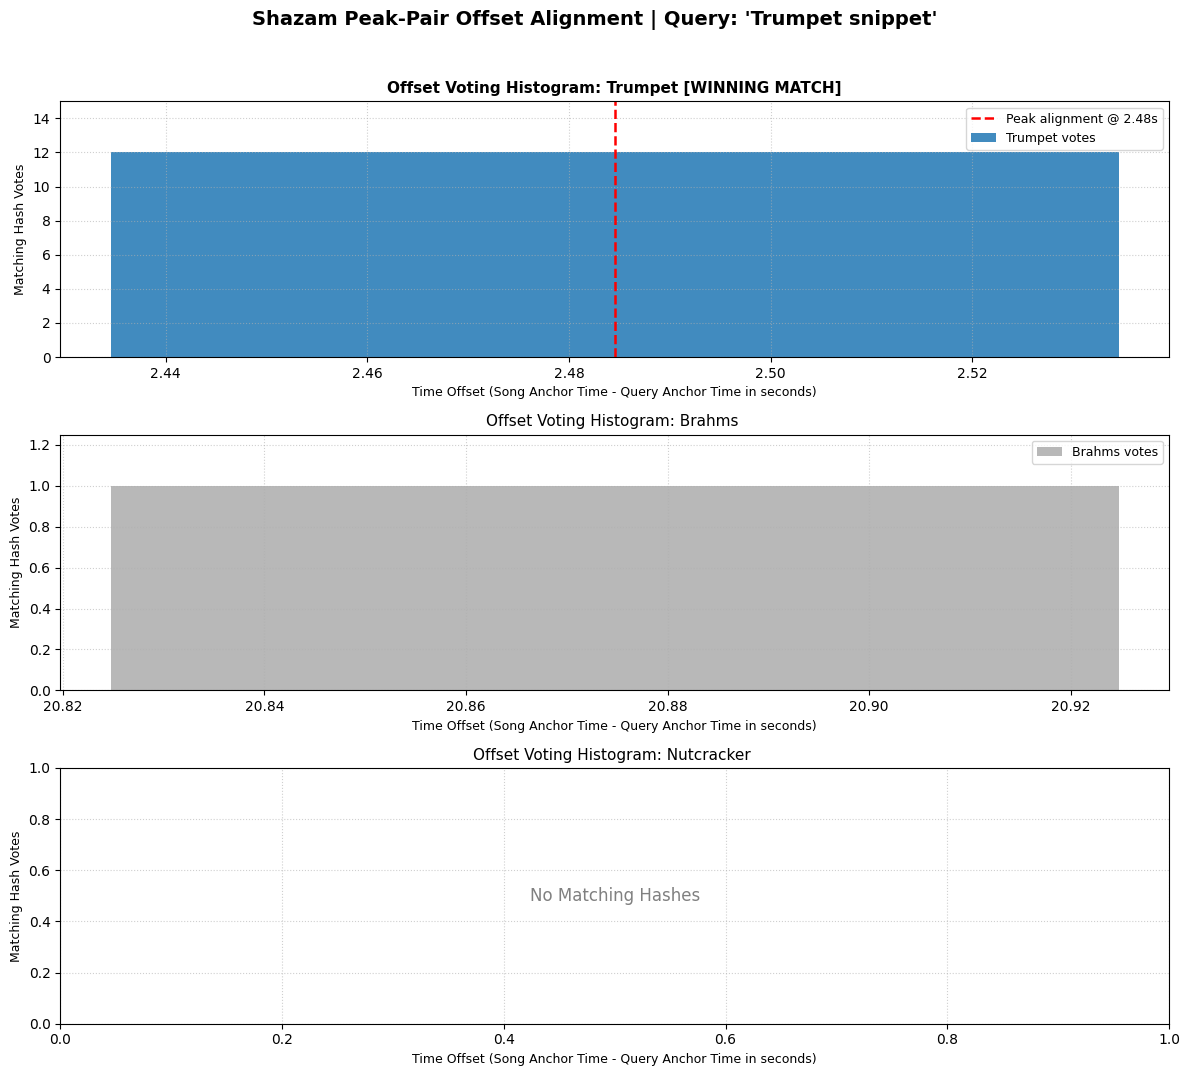

In [ ]:
# END-TO-END TEST FOR SHAZAM RECOGNITION (TASK 6)


def run_shazam_test():
    print("1. Loading sample audio files into database...")
    paths = {
        "Trumpet": librosa.ex('trumpet'),
        "Brahms": librosa.ex('brahms'),
        "Nutcracker": librosa.ex('nutcracker')
    }

    songs_dict = {}
    for name, path in paths.items():
        y, sr = load_audio(path, target_srate=TARGET_SRATE, normalize=True)
        songs_dict[name] = (y, sr)
        print(f"   - Loaded '{name}'")

    # 2. Define query parameters and ALIGN to STFT grid
    test_song = "Trumpet"

    # Snap the start time perfectly to the STFT hop_length grid to avoid blurring
    raw_start_sample = int(2.5 * TARGET_SRATE)
    aligned_start_sample = raw_start_sample - (raw_start_sample % HOP_LENGTH)
    start_time_sec = aligned_start_sample / TARGET_SRATE
    duration_sec = 4.0

    print(f"\n2. Extracting {duration_sec}s query from '{test_song}'...")
    test_y, test_sr = songs_dict[test_song]

    # Extract query WITHOUT noise first to verify core math
    query_audio = extract_query_clip(
        y=test_y, sr=test_sr, start_sec=start_time_sec, duration_sec=duration_sec, noise_snr_db=None
    )

    print("\n3. Running Shazam recognition algorithm...")
    predicted_song, best_offset_sec, best_score, offset_histograms = identify_query_clip_shazam(
        query_audio=query_audio, songs_dict=songs_dict
    )

    print("\n" + "="*40)
    print(" RECOGNITION RESULTS")
    print("="*40)
    print(f"Expected Song:     {test_song}")
    print(f"Predicted Song:    {predicted_song}")
    print(f"Peak Votes:        {best_score}")

    if predicted_song == test_song:
        print("\n✅ SUCCESS: The algorithm correctly identified the song!")
    else:
        print("\n❌ FAILED: The algorithm did not find the correct match.")

    print("\n4. Plotting Offset Voting Histogram...")
    fig = plot_offset_voting_histogram(
        offset_histograms=offset_histograms,
        predicted_song=predicted_song,
        best_offset_sec=best_offset_sec,
        query_label=f"{test_song} snippet"
    )
    plt.show()

# Run the test
run_shazam_test()

## Group 3 amendment to Task 6 - check that only real peaks are detected
While testing Task 10, Group 3 found that Task 6's peak detector counted **flat, quiet regions** of the spectrogram
as peaks. `amplitude_to_db` (librosa's default `top_db=80`) flattened everything more than 80 dB below a clip's
loudest point to one identical value; for loud clips that value was above the -40 dB peak threshold, so every cell
of a quiet passage passed as a "peak". Measured on the original code, before the amendment:

| Clip (3 s) | Peaks | Fake (flat-region) peaks | Hashes | Distinct hashes |
|---|---|---|---|---|
| Song3 starting at 116.9 s (the last 3 s of the piece) | 12,658 | 12,623 | 82,998 | 6,661 |
| Song1 starting at 0.6 s | 2,330 | 2,248 | 13,312 | 4,286 |

The fake peaks also survived pitch shifting (Song3: 13,744 fake peaks after +0.5 semitone), which inflated the
peak-pair votes in the experiments. After the amendment, the check below reports **0 flat-region peaks in all 15 clips**: the
Song3 clip at 116.9 s now has 35 peaks and 105 hashes, and the Song1 clip at 0.6 s has 82 peaks and 464 hashes.
All Group 3 results in this notebook were produced after the amendment. Task 6's `comp_spectrogram` now uses `top_db=None` (one line, marked
*AMENDED BY GROUP 3*). The cell below re-checks 5 clips per song: a **flat-region peak** is a "peak" whose value
exactly equals a direct neighbour, which a real local maximum of music does not do.

In [82]:
# ============================================================
# GROUP 3 CHECK OF THE TASK 6 AMENDMENT
# Uses only Task 1 (songs) and Task 6 (ShazamPeakPairRecogniser). Runs before Tasks 8-10.
# ============================================================
import numpy as np
import pandas as pd


def count_flat_region_peaks(peaks, spec_db):
    """Number of detected peaks that have a direct neighbour with EXACTLY the same dB value.
    A real local maximum stands above its neighbours; equal neighbours mean a flat region."""
    n_freq, n_time = spec_db.shape
    flat = 0
    for f, t, _ in peaks:
        for df, dt in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            ff, tt = f + df, t + dt
            if 0 <= ff < n_freq and 0 <= tt < n_time and spec_db[ff, tt] == spec_db[f, t]:
                flat += 1
                break
    return flat


checker = ShazamPeakPairRecogniser()   # only used to extract peaks/hashes, no database needed
rows = []
for song, (y, sr) in songs.items():
    clip_len = int(3 * sr)                                       # 3 s clips, as in Tasks 9 and 10
    for start in np.linspace(0, len(y) - clip_len, 5).astype(int):   # 5 clips spread through the song
        hashes, peaks, spec_db = checker.extract_fingerprints(y[start:start + clip_len])
        keys = [h for h, _ in hashes]
        rows.append({"song": song, "start_s": round(start / sr, 1), "peaks": len(peaks),
                     "flat_region_peaks": count_flat_region_peaks(peaks, spec_db),
                     "hashes": len(keys), "distinct_hashes": len(set(keys))})
peak_check = pd.DataFrame(rows)
print(peak_check.to_string(index=False))
total_flat = int(peak_check["flat_region_peaks"].sum())
print(f"\nFlat-region peaks in all {len(peak_check)} clips: {total_flat}  ->  "
      f"{'OK: only real peaks are detected' if total_flat == 0 else 'CHECK: flat-region peaks still present'}")

 song  start_s  peaks  flat_region_peaks  hashes  distinct_hashes
Song1      0.0      6                  0       8                8
Song1     14.2      6                  0       8                4
Song1     28.5      6                  0       8                8
Song1     42.7      6                  0       8                4
Song1     57.0      6                  0       8                8
Song2      0.0     13                  0      44               17
Song2     14.2     13                  0      45               16
Song2     28.5     13                  0      44               17
Song2     42.7     13                  0      45               16
Song2     57.0     13                  0      44               17
Song3      0.0     10                  0       9                5
Song3     14.2      9                  0       7                3
Song3     28.5     10                  0       9                5
Song3     42.7      9                  0       7                3
Song3     

# Group 3 - Task 8: Query-length and starting-position study

**Goal:** measure how recognition performance changes with (a) how long the query clip is and
(b) where in the song the clip starts, for BOTH recognisers (Task 5 baseline, Task 6 peak-pair).

**Run this AFTER the Task 1-6 cells.** It needs these names from them:
`songs` (dict name -> (audio, sr)), `BaselineSpectralRecogniser`, `ShazamPeakPairRecogniser`, `HOP_LENGTH`.

### Three visual indicators produced
1. **Accuracy vs query length** - how long must a clip be before each method is reliable?
2. **Recognition map** (start time x length, green = right, red = wrong) - *where* in each song does it fail?
3. **Confidence margin vs query length** - how close was the runner-up song? Shows a method getting shaky before accuracy drops.

---
### Notes for whoever extends this to Task 9 (noise) and Task 10 (pitch / time-stretch)
The code is split into small pieces so Tasks 9 and 10 only need to touch two places:

| Piece | What it does | What Task 9 / 10 change |
|---|---|---|
| `METHODS` | dict name -> function `(query, sr) -> {"pred", "scores", "est_start"}` | Nothing. Task 10 compares these same two methods. |
| `TRANSFORMS` | dict name -> function `(clip, sr, value) -> clip` applied inside `make_query` | **Register new ones**, e.g. `TRANSFORMS["snr_db"] = add_noise` |
| `run_experiment(..., conditions=[{...}, ...])` | loops songs x lengths x starts x conditions x methods | Pass `conditions=[{"snr_db": 20}, {"snr_db": 10}, ...]` and a single length, e.g. `lengths_sec=[5]` |
| Result `DataFrame` | one row per query: `song, method, length_sec, start_sec, start_frac, start_region, pred, correct, score, margin, est_start, offset_err` + one column per transform key | Nothing. Transform values become extra columns (e.g. `snr_db`). |
| `plot_accuracy_vs(df, x=...)`, `plot_margin_vs(df, x=...)` | generic line plots | Pass `x="snr_db"` / `x="pitch_steps"` / `x="stretch"` |
| `plot_recognition_map` | Task 8 specific (start x length) | Filter `df` to one condition first if reused |

Conventions: audio is mono float, sr = `TARGET_SRATE` (22050). A query is correct when `pred == song`.
`pred is None` means the method found nothing to vote for (counts as wrong).

## 1. Setup and settings

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- make sure the earlier tasks have been run ----
for _needed in ["songs", "BaselineSpectralRecogniser", "ShazamPeakPairRecogniser", "HOP_LENGTH"]:
    assert _needed in globals(), f"'{_needed}' not found - run the Task 1-6 cells first."

# ---- experiment settings (change these freely) ----
LENGTHS_SEC = [0.5, 1, 2, 3, 5, 8, 10, 15]  # query durations to test. Lengths longer than a song are skipped
                                            # for that song (the trumpet clip is only ~5 s long).
N_STARTS = 15            # start positions per (song, length), evenly spread from song start to the last valid start
SNAP_START_TO_HOP = False  # False = realistic (query can start anywhere).
                           # True  = round starts down to the STFT hop grid, like the Task 6 test (ideal case).
RELIABLE_ACCURACY = 0.9  # accuracy needed to call a query length "reliable"

## 2. Recognition methods (one uniform interface)
Each method is a function `method(query_audio, sr) -> dict` with keys:
* `pred` - predicted song name (or `None` if nothing matched)
* `scores` - dict `{song_name: score}` for every song (cosine similarity for the baseline, vote count for peak-pair)
* `est_start` - estimated start time of the query inside the song in seconds (`nan` if the method can't say)

The databases are built **once** here, not once per query, so the experiment runs fast.

In [84]:
def make_baseline_method(songs):
    """Task 5: average-spectrum cosine similarity."""
    rec = BaselineSpectralRecogniser()
    for name, (y, sr) in songs.items():
        rec.index_song(name, y, sr)

    def method(query, sr):
        pred, _, ranked = rec.recognize(query, sr)   # ranked = [(song, similarity), ...]
        return {"pred": pred, "scores": dict(ranked), "est_start": np.nan}
    return method


def make_peak_pair_method(songs):
    """Task 6: Shazam-style peak-pair hashing with offset voting."""
    rec = ShazamPeakPairRecogniser()
    for name, (y, sr) in songs.items():
        rec.index_song(name, y)

    def method(query, sr):
        try:
            pred, offset_sec, _, _, board = rec.recognize(query)  # board = [(song, votes, offset, conf), ...]
        except ValueError:
            # raised when the query has no peaks at all (too short / silent) -> no answer
            return {"pred": None, "scores": {n: 0 for n in songs}, "est_start": np.nan}
        scores = {name: votes for name, votes, _, _ in board}
        if max(scores.values()) == 0:      # no hash matched anywhere -> don't let a tie look like a guess
            return {"pred": None, "scores": scores, "est_start": np.nan}
        return {"pred": pred, "scores": scores, "est_start": offset_sec}
    return method


METHODS = {
    "baseline":  make_baseline_method(songs),
    "peak_pair": make_peak_pair_method(songs),
}
print("Methods ready:", list(METHODS))

Methods ready: ['baseline', 'peak_pair']


## 3. Building a query clip
`make_query` cuts a clip out of a song. Task 8 only uses `start_sec` and `length_sec`.
Tasks 9 / 10 add modifications by registering functions in `TRANSFORMS` (empty for Task 8).

In [85]:
# name -> function(clip, sr, value) -> modified clip.   Examples for later tasks (NOT used in Task 8):
#   TRANSFORMS["snr_db"]      = lambda clip, sr, snr: add_noise(clip, snr)
#   TRANSFORMS["pitch_steps"] = lambda clip, sr, n: librosa.effects.pitch_shift(clip, sr=sr, n_steps=n)
#   TRANSFORMS["stretch"]     = lambda clip, sr, r: librosa.effects.time_stretch(clip, rate=r)
TRANSFORMS = {}


def make_query(y, sr, start_sec, length_sec, **transforms):
    """Cut [start_sec, start_sec + length_sec] from y, then apply any requested transforms.
    Returns (clip, start_sec_actually_used)."""
    start_sample = int(round(start_sec * sr))
    if SNAP_START_TO_HOP:
        start_sample -= start_sample % HOP_LENGTH      # align with the STFT frame grid
    clip = y[start_sample : start_sample + int(round(length_sec * sr))].copy()

    for name, value in transforms.items():             # e.g. name="snr_db", value=10
        clip = TRANSFORMS[name](clip, sr, value)
    return clip, start_sample / sr

## 4. The experiment loop
For every song x length x start x condition, cut a query, ask every method, and store one row.

In [86]:
def run_experiment(songs, methods, lengths_sec, n_starts, conditions=None):
    """Returns a DataFrame with one row per (query, method).

    conditions: list of dicts of transform values, e.g. [{"snr_db": 20}, {"snr_db": 5}].
                Default [{}] = no modification (Task 8).
    """
    conditions = conditions or [{}]
    rows = []
    for song, (y, sr) in songs.items():
        duration = len(y) / sr
        for length in lengths_sec:
            if length > duration:                       # clip shorter than the query -> skip
                continue
            max_start = duration - length               # last start that still fits inside the song
            for frac in np.linspace(0, 1, n_starts):    # frac = how far along the valid range we start
                for cond in conditions:
                    query, start = make_query(y, sr, frac * max_start, length, **cond)
                    for mname, method in methods.items():
                        out = method(query, sr)
                        scores = sorted(out["scores"].values(), reverse=True)
                        top1, top2 = scores[0], (scores[1] if len(scores) > 1 else 0)
                        # margin in [0,1]: 0 = runner-up tied with winner, 1 = runner-up got nothing
                        margin = float(np.clip((top1 - top2) / top1, 0, 1)) if top1 > 0 else 0.0
                        row = {
                            "song": song, "method": mname,
                            "length_sec": length, "start_sec": start, "start_frac": frac,
                            "start_region": "begin" if frac < 1/3 else ("middle" if frac < 2/3 else "end"),
                            "pred": out["pred"], "correct": int(out["pred"] == song),
                            "score": top1, "margin": margin,
                            "est_start": out["est_start"], "offset_err": out["est_start"] - start,
                        }
                        row.update(cond)                # transform values become extra columns
                        rows.append(row)
    return pd.DataFrame(rows)

In [87]:
results = run_experiment(songs, METHODS, LENGTHS_SEC, N_STARTS)
results.to_csv("task8_results.csv", index=False)      # Tasks 9/10 can reuse the same column layout
print(f"{len(results)} rows saved to task8_results.csv")

# ---- quick tables ----
print("\nAccuracy by method and query length:")
print(results.pivot_table(index="length_sec", columns="method", values="correct", aggfunc="mean").round(2))

print("\nAccuracy by start region (first / middle / last third of the song):")
print(results.pivot_table(index=["method", "length_sec"], columns="start_region",
                          values="correct", aggfunc="mean")[["begin", "middle", "end"]].round(2))

720 rows saved to task8_results.csv

Accuracy by method and query length:
method      baseline  peak_pair
length_sec                     
0.5              1.0       0.33
1.0              1.0       0.80
2.0              1.0       1.00
3.0              1.0       1.00
5.0              1.0       1.00
8.0              1.0       1.00
10.0             1.0       1.00
15.0             1.0       1.00

Accuracy by start region (first / middle / last third of the song):
start_region          begin  middle   end
method    length_sec                     
baseline  0.5          1.00    1.00  1.00
          1.0          1.00    1.00  1.00
          2.0          1.00    1.00  1.00
          3.0          1.00    1.00  1.00
          5.0          1.00    1.00  1.00
          8.0          1.00    1.00  1.00
          10.0         1.00    1.00  1.00
          15.0         1.00    1.00  1.00
peak_pair 0.5          0.33    0.33  0.33
          1.0          0.80    0.87  0.73
          2.0          1.00    1.

## 5. Visual 1 - Accuracy vs query length
One panel per method. Thin coloured lines = individual songs, thick black line = all queries pooled.
Dotted line = chance level (guessing among the songs). Dashed green line = the "reliable" accuracy bar;
the vertical green line marks the shortest query length from which accuracy stays above that bar.

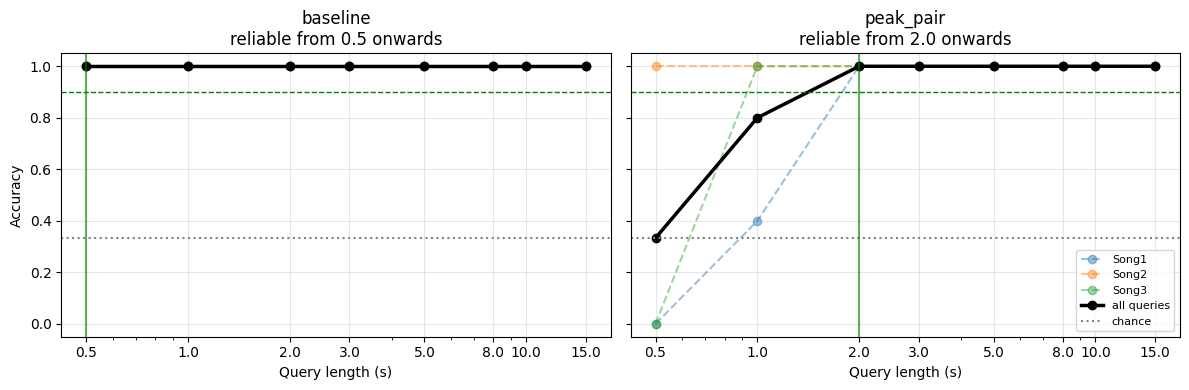

In [88]:
def min_reliable_x(acc, threshold):
    """Smallest x where accuracy >= threshold AND stays >= threshold for every larger x
    (assumes 'larger x = easier', true for query length and SNR)."""
    found = None
    for x in sorted(acc.index, reverse=True):
        if acc[x] >= threshold:
            found = x
        else:
            break
    return found


def plot_accuracy_vs(df, x="length_sec", xlabel="Query length (s)", log_x=False,
                     threshold=RELIABLE_ACCURACY, save_as=None):
    methods = list(df["method"].unique())
    chance = 1 / df["song"].nunique()
    fig, axes = plt.subplots(1, len(methods), figsize=(6 * len(methods), 4), sharey=True, squeeze=False)

    for ax, m in zip(axes[0], methods):
        d = df[df["method"] == m]
        for song, g in d.groupby("song"):                          # thin line per song
            a = g.groupby(x)["correct"].mean()
            ax.plot(a.index, a.values, "o--", alpha=0.45, label=song)
        mean = d.groupby(x)["correct"].mean()                      # thick pooled line
        ax.plot(mean.index, mean.values, "ko-", lw=2.5, label="all queries")

        ax.axhline(chance, color="gray", ls=":", label="chance")
        ax.axhline(threshold, color="green", ls="--", lw=1)
        best_x = min_reliable_x(mean, threshold)
        if best_x is not None:
            ax.axvline(best_x, color="green", alpha=0.6)
            ax.set_title(f"{m}\nreliable from {best_x} onwards")
        else:
            ax.set_title(f"{m}\nnever reaches {threshold:.0%}")
        if log_x:
            ax.set_xscale("log")
            ax.set_xticks(sorted(df[x].unique()))
            ax.set_xticklabels(sorted(df[x].unique()))
        ax.set_xlabel(xlabel)
        ax.set_ylim(-0.05, 1.05)
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("Accuracy")
    axes[0][-1].legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    if save_as:
        fig.savefig(save_as, dpi=150)
    plt.show()


plot_accuracy_vs(results, log_x=True, save_as="task8_accuracy_vs_length.png")

## 6. Visual 2 - Recognition map (start position x query length)
One panel per song. Each square is one query: **x** = where in the song the clip starts,
**y** = how long the clip is, **green** = identified correctly, **red** = wrong or no match.
A red patch at some start time means that part of the song is hard to recognise (e.g. a quiet or sparse passage).
A song shorter than a query length simply has no squares on that row.

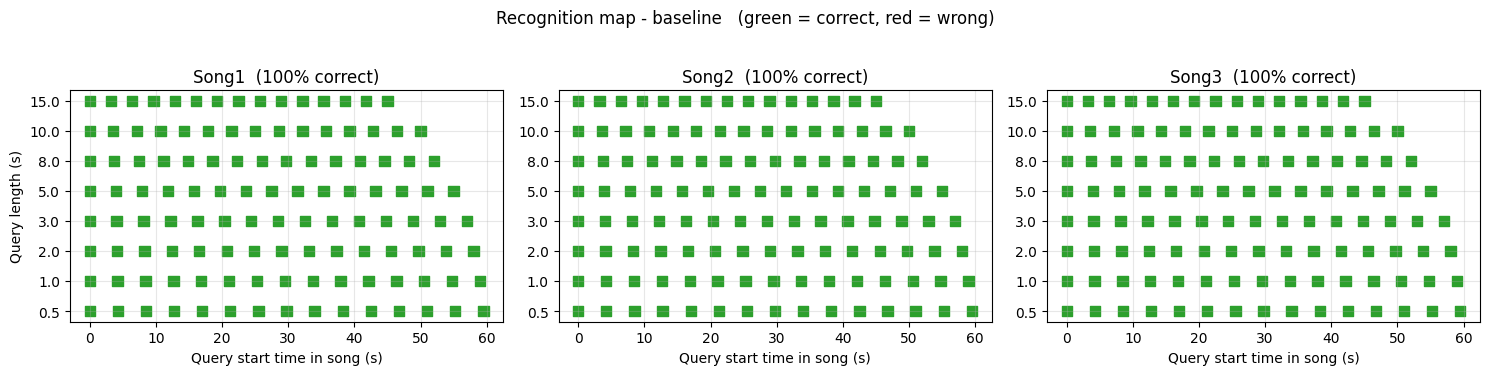

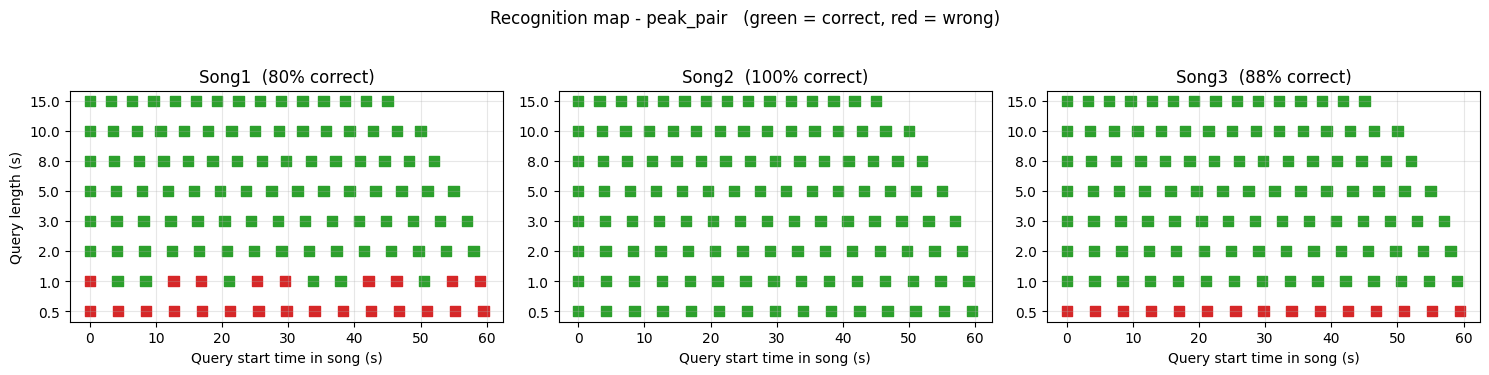

In [89]:
def plot_recognition_map(df, method, save_as=None):
    d = df[df["method"] == method]
    song_names = list(d["song"].unique())
    lengths = sorted(d["length_sec"].unique())
    row_of = {L: i for i, L in enumerate(lengths)}               # length -> row number on the y axis

    fig, axes = plt.subplots(1, len(song_names), figsize=(5 * len(song_names), 3.6), squeeze=False)
    for ax, s in zip(axes[0], song_names):
        g = d[d["song"] == s]
        colors = np.where(g["correct"] == 1, "tab:green", "tab:red")
        ax.scatter(g["start_sec"], g["length_sec"].map(row_of), c=colors, marker="s", s=55)
        ax.set_yticks(range(len(lengths)))
        ax.set_yticklabels(lengths)
        ax.set_title(f"{s}  ({g['correct'].mean():.0%} correct)")
        ax.set_xlabel("Query start time in song (s)")
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("Query length (s)")
    fig.suptitle(f"Recognition map - {method}   (green = correct, red = wrong)", y=1.03)
    fig.tight_layout()
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()


for m in METHODS:
    plot_recognition_map(results, m, save_as=f"task8_map_{m}.png")

## 7. Visual 3 - Confidence margin vs query length
Margin = (best score - runner-up score) / best score. **1** = the winner is far ahead, **0** = the runner-up is tied.
The band is mean +/- one standard deviation across queries. A margin that shrinks toward 0 warns that the method is
about to start making mistakes, even while its accuracy still looks fine.

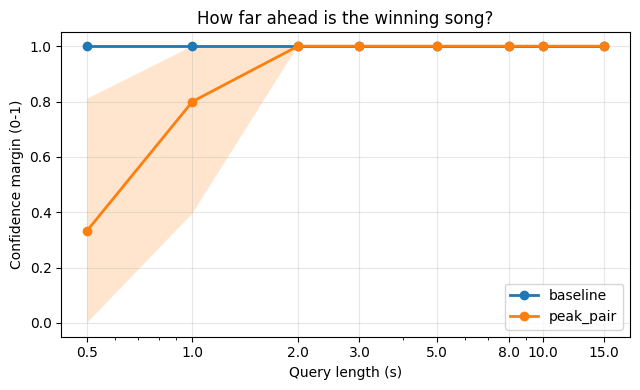

In [90]:
def plot_margin_vs(df, x="length_sec", xlabel="Query length (s)", log_x=False, save_as=None):
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for m, d in df.groupby("method"):
        g = d.groupby(x)["margin"]
        mean, std = g.mean(), g.std().fillna(0)
        ax.plot(mean.index, mean.values, "o-", lw=2, label=m)
        ax.fill_between(mean.index, (mean - std).clip(0, 1), (mean + std).clip(0, 1), alpha=0.2)
    if log_x:
        ax.set_xscale("log")
        ax.set_xticks(sorted(df[x].unique()))
        ax.set_xticklabels(sorted(df[x].unique()))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Confidence margin (0-1)")
    ax.set_ylim(-0.05, 1.05)
    ax.set_title("How far ahead is the winning song?")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    if save_as:
        fig.savefig(save_as, dpi=150)
    plt.show()


plot_margin_vs(results, log_x=True, save_as="task8_margin_vs_length.png")

## 8. Optional check - does the peak-pair method also find the right *time* in the song?
`offset_err` = estimated start - true start (seconds). Near 0 means the offset-voting histogram locked on correctly,
not just the song name. Only the peak-pair method has an estimate.

In [91]:
pp = results[(results["method"] == "peak_pair") & (results["correct"] == 1)]
print("Median |offset error| (s) per query length, correct peak-pair queries only:")
print(pp.groupby("length_sec")["offset_err"].apply(lambda e: np.median(np.abs(e))).round(3))

Median |offset error| (s) per query length, correct peak-pair queries only:
length_sec
0.5     29.425
1.0     27.475
2.0     29.000
3.0     23.082
5.0     17.623
8.0     16.318
10.0    18.120
15.0    11.759
Name: offset_err, dtype: float64


# Group 3 - Task 9: Noise robustness

**Goal:** measure how adding different amounts of background noise affects recognition, for BOTH recognisers
(Task 5 baseline, Task 6 peak-pair).

**Run this AFTER the Task 1-6 cells and the Task 8 cells** (Runtime -> Run all is the safe way).
It reuses these names from them and does **not** change any earlier cell:
`songs`, `METHODS`, `TRANSFORMS`, `make_query`, `run_experiment`, `plot_accuracy_vs`, `plot_margin_vs`,
`min_reliable_x`, `RELIABLE_ACCURACY`, `N_STARTS`, `ShazamPeakPairRecogniser`, `SAMPLE_COUNT`, `HOP_LENGTH`.

### Experiment design
| Decision | Choice | Why |
|---|---|---|
| Noise type | White Gaussian noise ("hiss") | The standard test noise; its strength can be set exactly |
| Noise levels (SNR) | clean, 30, 20, 10, 5, 0, -5, -10, -15, -20 dB | From barely audible to 100x louder than the music, so each method's breaking point is captured |
| Query length | 3 s, fixed | Song1 is only ~5.3 s long: 3 s clips still give it 15 clearly different start positions (5 s clips would all start within its first 0.3 s). Section 9.1 prints Task 8's clean accuracy at this length to confirm it is reliable |
| Start positions | 15 per song (same as Task 8) | The clean condition then reproduces Task 8's 3 s results exactly (checked in 9.4) |
| Random seed | 42 | The "random" noise is identical on every run, so results are reproducible |
| "Correct" | `pred == song` (Task 8's convention) | Keeps Tasks 8, 9 and 10 directly comparable |
| Confidence | `margin` (Task 8's column) and peak-pair `score` (votes) | Accuracy alone hides how close a method is to failing |

**What is SNR?** Signal-to-noise ratio in decibels: `SNR = 10 * log10(signal power / noise power)`.
+10 dB = music 10x stronger than the noise, 0 dB = equally strong, -10 dB = noise 10x stronger, -20 dB = noise 100x stronger.

### Visual indicators produced
1. **Accuracy vs SNR** - at what noise level does each method stop being reliable?
2. **Confidence margin vs SNR** - how close the runner-up song gets as noise rises.
3. **Peak-pair votes vs SNR** - how many matching hashes survive the noise.
4. **Which song does each method guess?** - does a method drift towards always guessing one song?
5. **Mechanism: what noise does to the peaks** - how many real peaks survive, and how many fake ones appear.

## 9.1 Setup and settings

In [92]:
# ============================================================
# GROUP 3 - TASK 9: NOISE ROBUSTNESS
# This code assumes that the Task 1-6 cells AND the Task 8 cells have already run.
# It REUSES these names from earlier cells (nothing in them is changed):
#   songs                    : dict name -> (audio, sr)                       (Group 1, Task 1)
#   METHODS                  : dict name -> recogniser function               (Task 8, section 2)
#   TRANSFORMS, make_query   : the hook Task 8 left for modifying query clips (Task 8, section 3)
#   run_experiment           : the experiment loop                            (Task 8, section 4)
#   plot_accuracy_vs, plot_margin_vs, min_reliable_x, RELIABLE_ACCURACY       (Task 8, sections 1, 5, 7)
#   ShazamPeakPairRecogniser : used here ONLY to look at peaks for the sanity checks (Task 6)
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display

# ---- make sure the earlier tasks have been run ----
for _needed in ["songs", "METHODS", "TRANSFORMS", "make_query", "run_experiment",
                "plot_accuracy_vs", "plot_margin_vs", "min_reliable_x", "RELIABLE_ACCURACY",
                "N_STARTS", "ShazamPeakPairRecogniser", "SAMPLE_COUNT", "HOP_LENGTH"]:
    assert _needed in globals(), f"'{_needed}' not found - run the Task 1-6 and Task 8 cells first."

# ---- experiment settings ----
# Noise levels as SNR in dB, from barely audible (30) to 100x louder than the music (-20).
# The range goes well below 0 dB so that the point where the peak-pair method breaks is captured.
T9_SNR_LEVELS_DB = [30, 20, 10, 5, 0, -5, -10, -15, -20]

# Query length in seconds, kept FIXED so that noise is the only thing that changes.
# Song1 is only ~5.3 s long: with 5 s clips its 15 "different" clips would all start within the first 0.3 s
# and be almost identical. 3 s gives every song clearly different clips.
# Task 8's clean accuracy at this length is printed below, so the choice can be checked against the data.
T9_LENGTH_SEC = 3

T9_N_STARTS = N_STARTS   # same 15 start positions per song as Task 8 -> clean results line up with Task 8
T9_SEED = 42             # fixed seed -> the "random" noise is the same on every run (reproducible)
CLEAN = np.inf           # infinite SNR = no noise at all; this is the clean reference condition

T9_DEMO_SONG = "Song2"   # song used for the listening / spectrogram checks (longest-but-one, ~46 s)
assert T9_DEMO_SONG in songs, f"{T9_DEMO_SONG} not in songs: {list(songs)}"

def noise_label(snr_db):
    """Readable name for a noise level: inf -> 'clean', 10 -> '10 dB'."""
    return "clean" if np.isinf(snr_db) else f"{snr_db:g} dB"

# Display order for tables: clean first, then from least to most noise.
T9_LEVEL_ORDER = [noise_label(CLEAN)] + [noise_label(s) for s in T9_SNR_LEVELS_DB]
# ---- check the chosen length against Task 8's clean results ----
if "results" in globals():
    t8_acc = results[results["length_sec"] == T9_LENGTH_SEC].groupby("method")["correct"].mean()
    print(f"Task 8 clean accuracy at {T9_LENGTH_SEC} s:", {m: f"{a:.0%}" for m, a in t8_acc.items()})
    if t8_acc.get("peak_pair", 0) < RELIABLE_ACCURACY:
        print(f"WARNING: peak_pair is below {RELIABLE_ACCURACY:.0%} on clean {T9_LENGTH_SEC} s clips; "
              "consider a longer T9_LENGTH_SEC.")
print("Noise levels:", T9_LEVEL_ORDER)
print(f"Query length: {T9_LENGTH_SEC} s, starts per song: {T9_N_STARTS}, seed: {T9_SEED}")

Task 8 clean accuracy at 3 s: {'baseline': '100%', 'peak_pair': '100%'}
Noise levels: ['clean', '30 dB', '20 dB', '10 dB', '5 dB', '0 dB', '-5 dB', '-10 dB', '-15 dB', '-20 dB']
Query length: 3 s, starts per song: 15, seed: 42


## 9.2 The noise function
`add_white_noise` uses **the same formula as Task 6's `extract_query_clip`**, with one change:
it takes a *seeded* random generator, so the noise (and every result below) is identical each time the
notebook runs. Task 6's version uses `np.random.normal` without a seed, so its noise changes on every run.

The function is registered in Task 8's `TRANSFORMS` hook under the name `snr_db`. Task 8's `run_experiment`
then adds the noise to every query clip, and `snr_db` becomes an extra column in the results.

In [93]:
def add_white_noise(clip, snr_db, rng):
    """Return clip + white Gaussian noise at the requested SNR (in dB).

    SNR_dB = 10 * log10(signal_power / noise_power)
      -> noise_power = signal_power / 10 ** (SNR_dB / 10)
    snr_db = inf (CLEAN) returns an untouched copy of the clip.
    """
    if np.isinf(snr_db):
        return clip.copy()

    # Power = average of the squared sample values (how "strong" the sound is on average).
    signal_power = np.mean(clip ** 2)
    noise_power = signal_power / (10 ** (snr_db / 10))

    # standard_normal() gives random noise with power 1. Multiplying by sqrt(noise_power)
    # scales it to exactly the power we want. max(..., 1e-12) protects against a silent clip.
    noise = rng.standard_normal(len(clip)) * np.sqrt(max(noise_power, 1e-12))
    return clip + noise


def measure_snr_db(clean, noisy):
    """Measure the SNR actually achieved: compare the clean clip with the noise that was added."""
    added_noise = noisy - clean
    return 10 * np.log10(np.mean(clean ** 2) / np.mean(added_noise ** 2))


# One seeded generator shared by every noisy query. It is reset right before the main run (section 9.4).
T9_RNG = np.random.default_rng(T9_SEED)

# Register the noise in Task 8's hook. make_query calls TRANSFORMS[name](clip, sr, value),
# so passing conditions like {"snr_db": 10} to run_experiment adds 10 dB noise to every query.
TRANSFORMS["snr_db"] = lambda clip, sr, snr: add_white_noise(clip, snr, T9_RNG)
print("Registered transforms:", list(TRANSFORMS))

Registered transforms: ['snr_db']


## 9.3 Sanity checks (before trusting any results)
1. **Is the noise really at the level we asked for?** Measure the SNR after adding it.
2. **Listen to it.** Clean, 10 dB, 0 dB and -10 dB versions of the same clip.
   (The players auto-adjust the volume, so the noisy versions do not play louder.)
3. **Look at it.** Spectrograms with the peaks that Task 6's recogniser actually uses.

These checks use their own random generator, so they do not change the main experiment.

In [94]:
# ---- Check 1: target SNR vs measured SNR ----
demo_y, demo_sr = songs[T9_DEMO_SONG]
demo_clip, _ = make_query(demo_y, demo_sr, start_sec=10.0, length_sec=T9_LENGTH_SEC)  # no noise yet
check_rng = np.random.default_rng(T9_SEED + 100)   # separate generator, so the main run is unaffected

snr_check = pd.DataFrame([
    {"target SNR (dB)": snr,
     "measured SNR (dB)": round(measure_snr_db(demo_clip, add_white_noise(demo_clip, snr, check_rng)), 2)}
    for snr in T9_SNR_LEVELS_DB
])
print(f"SNR check on a {T9_LENGTH_SEC} s clip of {T9_DEMO_SONG}:")
print(snr_check.to_string(index=False))
worst_error = (snr_check["measured SNR (dB)"] - snr_check["target SNR (dB)"]).abs().max()
print(f"\nLargest difference: {worst_error:.2f} dB  ->  {'OK' if worst_error < 0.5 else 'CHECK add_white_noise'}")

SNR check on a 3 s clip of Song2:
 target SNR (dB)  measured SNR (dB)
              30              30.02
              20              20.01
              10               9.98
               5               5.02
               0              -0.01
              -5              -5.01
             -10             -10.01
             -15             -15.01
             -20             -20.01

Largest difference: 0.02 dB  ->  OK


In [95]:
# ---- Check 2: listen to the same clip at different noise levels ----
for snr in [CLEAN, 10, 0, -10]:
    print(f"{T9_DEMO_SONG}, {noise_label(snr)}:")
    display(Audio(add_white_noise(demo_clip, snr, check_rng), rate=demo_sr))

Song2, clean:


Song2, 10 dB:


Song2, 0 dB:


Song2, -10 dB:


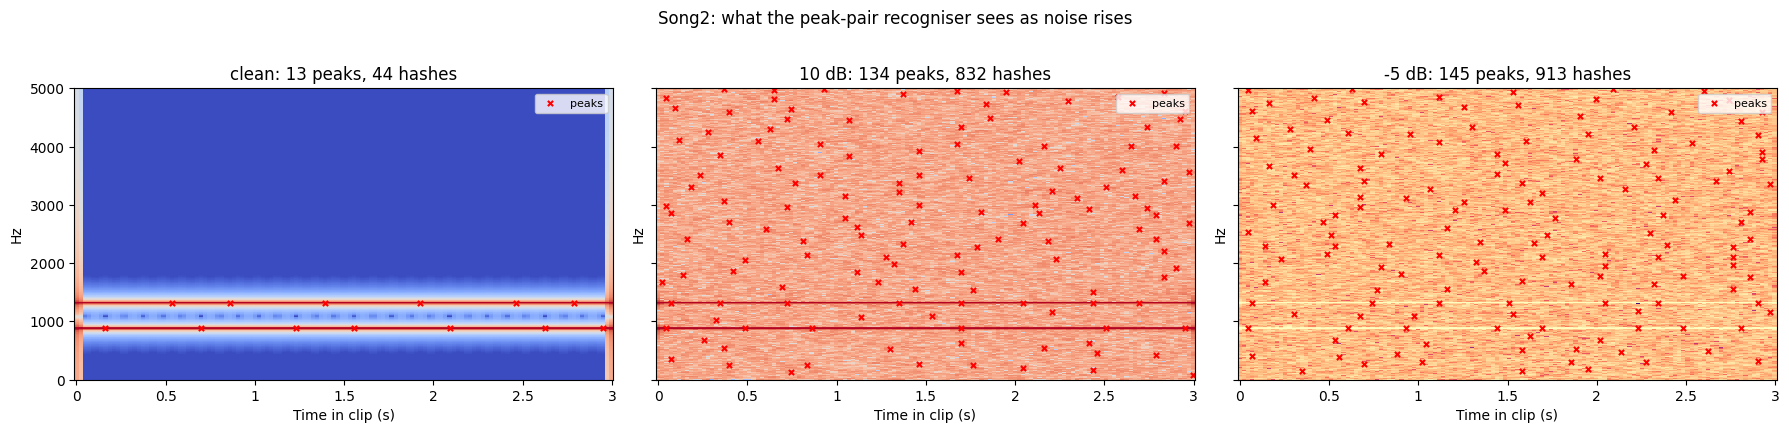

In [96]:
# ---- Check 3: spectrograms + the peaks Task 6's recogniser extracts ----
# extract_fingerprints() returns (hashes, peaks, spectrogram) exactly as the recogniser computes them.
# Each peak is (frequency bin, time frame, loudness in dB).
viewer = ShazamPeakPairRecogniser()
show_levels = [CLEAN, 10, -5]

fig, axes = plt.subplots(1, len(show_levels), figsize=(6 * len(show_levels), 4.2), sharey=True)
for ax, snr in zip(axes, show_levels):
    clip = add_white_noise(demo_clip, snr, check_rng)
    hashes, peaks, spec_db = viewer.extract_fingerprints(clip)

    librosa.display.specshow(spec_db, sr=demo_sr, hop_length=HOP_LENGTH, n_fft=SAMPLE_COUNT,
                             x_axis="time", y_axis="hz", ax=ax, vmin=-60, vmax=40)
    if peaks:
        f_bins = np.array([p[0] for p in peaks])
        t_frames = np.array([p[1] for p in peaks])
        ax.scatter(librosa.frames_to_time(t_frames, sr=demo_sr, hop_length=HOP_LENGTH),
                   f_bins * demo_sr / SAMPLE_COUNT, s=14, c="red", marker="x", label="peaks")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_ylim(0, 5000)   # Task 6 only looks for peaks below 5000 Hz
    ax.set_title(f"{noise_label(snr)}: {len(peaks)} peaks, {len(hashes)} hashes")
    ax.set_xlabel("Time in clip (s)")
fig.suptitle(f"{T9_DEMO_SONG}: what the peak-pair recogniser sees as noise rises", y=1.02)
fig.tight_layout()
plt.show()

## 9.4 The experiment
One call to Task 8's `run_experiment`, with one condition per noise level. For every song x start position x
noise level, it cuts a 3 s query, adds the noise, asks both methods, and stores one row per method.

The random generator is reset at the top of this cell, so re-running **this cell alone** also reproduces the
same numbers. The clean condition is then compared with Task 8's 3 s results: they must match exactly,
because the clips are identical.

In [97]:
T9_CONDITIONS = [{"snr_db": CLEAN}] + [{"snr_db": s} for s in T9_SNR_LEVELS_DB]

T9_RNG = np.random.default_rng(T9_SEED)   # reset -> identical noise every time this cell runs

t0 = time.time()
results_t9 = run_experiment(songs, METHODS, [T9_LENGTH_SEC], T9_N_STARTS, conditions=T9_CONDITIONS)
print(f"{len(results_t9)} rows in {time.time() - t0:.0f} s  "
      f"({len(songs)} songs x {T9_N_STARTS} starts x {len(T9_CONDITIONS)} noise levels x {len(METHODS)} methods)")

# Readable noise-level column, ordered clean -> most noise (used for the tables).
results_t9["noise_level"] = pd.Categorical(results_t9["snr_db"].map(noise_label),
                                           categories=T9_LEVEL_ORDER, ordered=True)

results_t9.to_csv("task9_results.csv", index=False)   # same columns as task8_results.csv + snr_db, noise_level
print("Saved to task9_results.csv")

# ---- Check 4: the clean condition must reproduce Task 8 at the same length ----
clean_t9 = results_t9[np.isinf(results_t9["snr_db"])].groupby("method")["correct"].mean()
if "results" in globals():
    clean_t8 = results[results["length_sec"] == T9_LENGTH_SEC].groupby("method")["correct"].mean()
    check = pd.DataFrame({f"Task 8 ({T9_LENGTH_SEC} s)": clean_t8, "Task 9 clean": clean_t9}).round(3)
    print("\nClean accuracy, Task 8 vs Task 9 (should be identical):")
    print(check)
    print("-> MATCH" if np.allclose(check.iloc[:, 0], check.iloc[:, 1]) else "-> MISMATCH: check settings")
else:
    print("\nTask 8 results not in memory (run the Task 8 cells to compare). Task 9 clean accuracy:")
    print(clean_t9.round(3))

900 rows in 13 s  (3 songs x 15 starts x 10 noise levels x 2 methods)
Saved to task9_results.csv

Clean accuracy, Task 8 vs Task 9 (should be identical):
           Task 8 (3 s)  Task 9 clean
method                               
baseline            1.0           1.0
peak_pair           1.0           1.0
-> MATCH


## 9.5 Results tables

In [98]:
# observed=True: only show noise levels that were actually tested (also avoids a pandas warning).
print("Accuracy (%) by noise level and method:")
acc_table = results_t9.pivot_table(index="noise_level", columns="method", values="correct",
                                   aggfunc="mean", observed=True)
print((acc_table * 100).round(1))

print("\nAccuracy (%) by noise level, method and song:")
song_table = results_t9.pivot_table(index="noise_level", columns=["method", "song"], values="correct",
                                    aggfunc="mean", observed=True)
print((song_table * 100).round(1))

print("\nAverage confidence margin (0 = runner-up tied, 1 = runner-up got nothing):")
print(results_t9.pivot_table(index="noise_level", columns="method", values="margin",
                             aggfunc="mean", observed=True).round(2))

print("\nPeak-pair: average votes for the winning song:")
print(results_t9[results_t9["method"] == "peak_pair"]
      .pivot_table(index="noise_level", columns="song", values="score", aggfunc="mean", observed=True).round(1))

print("\nQueries with no answer at all (pred is None):")
print(results_t9.assign(no_answer=results_t9["pred"].isna())
      .pivot_table(index="noise_level", columns="method", values="no_answer", aggfunc="sum", observed=True))

Accuracy (%) by noise level and method:
method       baseline  peak_pair
noise_level                     
clean           100.0      100.0
30 dB           100.0       75.6
20 dB           100.0       77.8
10 dB           100.0       71.1
5 dB            100.0       77.8
0 dB            100.0       62.2
-5 dB           100.0       71.1
-10 dB          100.0       64.4
-15 dB          100.0       53.3
-20 dB          100.0       42.2

Accuracy (%) by noise level, method and song:
method      baseline               peak_pair              
song           Song1  Song2  Song3     Song1  Song2  Song3
noise_level                                               
clean          100.0  100.0  100.0     100.0  100.0  100.0
30 dB          100.0  100.0  100.0      80.0   86.7   60.0
20 dB          100.0  100.0  100.0      73.3  100.0   60.0
10 dB          100.0  100.0  100.0      80.0   60.0   73.3
5 dB           100.0  100.0  100.0      66.7  100.0   66.7
0 dB           100.0  100.0  100.0      66.7 

## 9.6 Visual 1 - Accuracy vs noise level
Task 8's `plot_accuracy_vs`, with SNR on the x axis instead of query length. Higher SNR = cleaner, so the
**right-hand side is clean** and noise increases to the left. Thin lines = individual songs, thick black
line = all queries pooled, dotted line = chance (guessing among the 3 songs), dashed green line = the 90%
"reliable" bar. **"Reliable from X onwards"** in the title means: accuracy stays above 90% at X dB and at every
cleaner level. The clean (no noise) accuracy is in the 9.5 table.

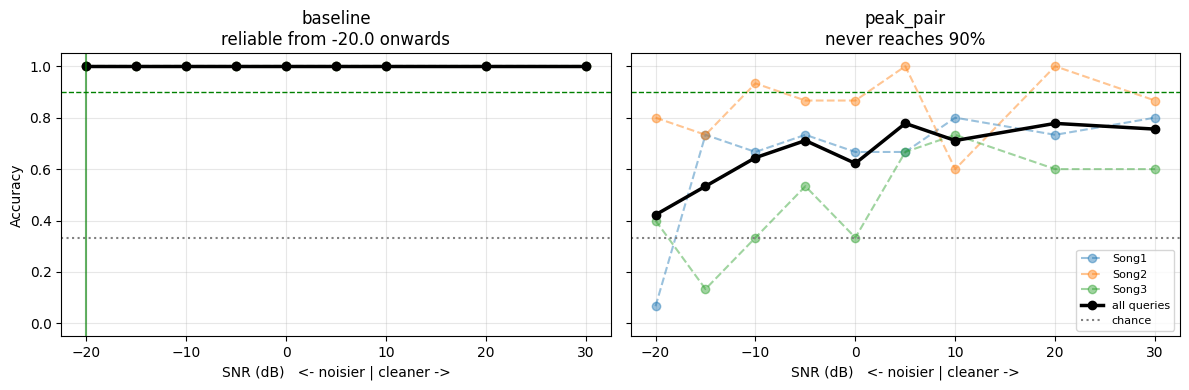

In [99]:
noisy_t9 = results_t9[np.isfinite(results_t9["snr_db"])]   # all rows except the clean reference

plot_accuracy_vs(noisy_t9, x="snr_db", xlabel="SNR (dB)   <- noisier | cleaner ->",
                 save_as="task9_accuracy_vs_snr.png")

## 9.7 Visual 2 - Confidence margin vs noise level
Task 8's `plot_margin_vs`. A margin that shrinks towards 0 shows a method getting shaky *before* its accuracy drops.

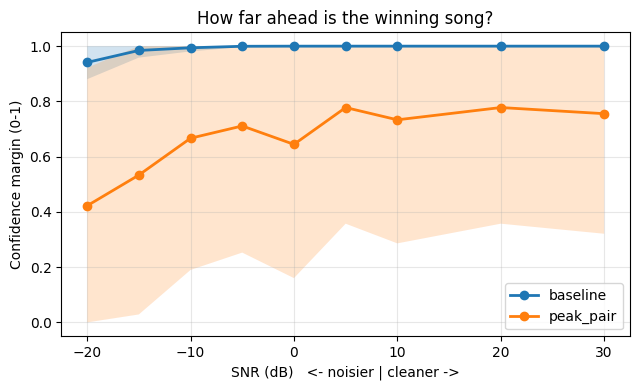

In [100]:
plot_margin_vs(noisy_t9, x="snr_db", xlabel="SNR (dB)   <- noisier | cleaner ->",
               save_as="task9_margin_vs_snr.png")

## 9.8 Visual 3 - Peak-pair votes vs noise level
Votes = number of matching hashes that line up at the winning time offset. The dotted line of the same colour
is the same song with **no** noise. Falling votes mean fewer fingerprints survive the noise, even while the
answer may still be right.

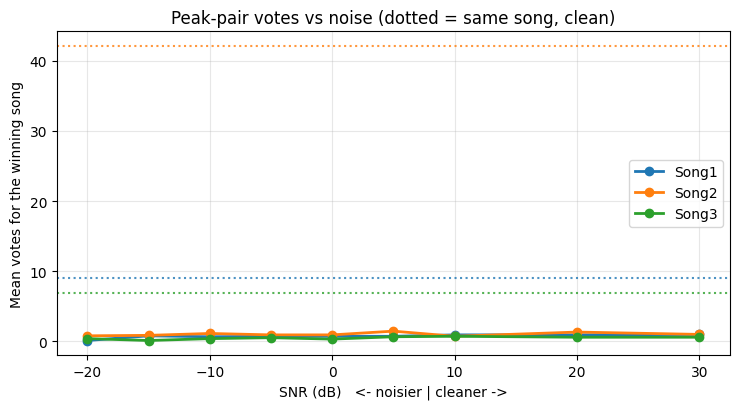

In [101]:
pp_t9 = results_t9[results_t9["method"] == "peak_pair"]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for song, g in pp_t9[np.isfinite(pp_t9["snr_db"])].groupby("song"):
    votes = g.groupby("snr_db")["score"].mean()                               # mean votes per noise level
    line, = ax.plot(votes.index, votes.values, "o-", lw=2, label=song)
    clean_votes = pp_t9[(pp_t9["song"] == song) & np.isinf(pp_t9["snr_db"])]["score"].mean()
    ax.axhline(clean_votes, color=line.get_color(), ls=":", alpha=0.8)      # same song, no noise

ax.set_xlabel("SNR (dB)   <- noisier | cleaner ->")
ax.set_ylabel("Mean votes for the winning song")
ax.set_title("Peak-pair votes vs noise (dotted = same song, clean)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("task9_votes_vs_snr.png", dpi=150)
plt.show()

## 9.9 Visual 4 - Which song does each method guess?
For each noise level: the share of all queries that were answered with each song. The test is balanced
(every song has the same number of queries), so a method that still works keeps every line near **1/3**
(dotted). If one line climbs towards 1, that method has started guessing the same song for almost everything.
"no match" = the method found nothing to vote for.

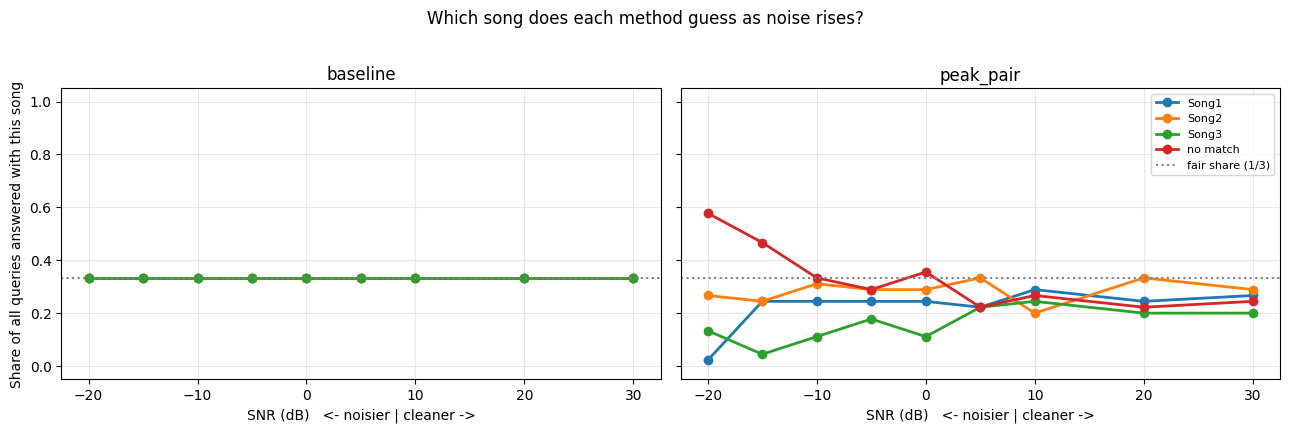


baseline at -20 dB  (rows = true song, columns = guessed song):
pred   Song1  Song2  Song3
song                      
Song1     15      0      0
Song2      0     15      0
Song3      0      0     15

peak_pair at -20 dB  (rows = true song, columns = guessed song):
pred   Song1  Song2  Song3  no match
song                                
Song1      1      0      0        14
Song2      0     12      0         3
Song3      0      0      6         9


In [102]:
n_songs = len(songs)
fig, axes = plt.subplots(1, len(METHODS), figsize=(6.5 * len(METHODS), 4.2), sharey=True, squeeze=False)

for ax, m in zip(axes[0], METHODS):
    d = noisy_t9[noisy_t9["method"] == m]
    guesses = d["pred"].where(d["pred"].notna(), "no match")             # None -> "no match"
    share = pd.crosstab(d["snr_db"], guesses, normalize="index")         # each row sums to 1
    for col in share.columns:
        ax.plot(share.index, share[col].values, "o-", lw=2, label=col)
    ax.axhline(1 / n_songs, color="gray", ls=":", label="fair share (1/3)")
    ax.set_title(m)
    ax.set_xlabel("SNR (dB)   <- noisier | cleaner ->")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.3)
axes[0][0].set_ylabel("Share of all queries answered with this song")
axes[0][-1].legend(fontsize=8)
fig.suptitle("Which song does each method guess as noise rises?", y=1.02)
fig.tight_layout()
fig.savefig("task9_guess_share_vs_snr.png", dpi=150, bbox_inches="tight")
plt.show()

# Full confusion table at the noisiest level: rows = true song, columns = guessed song.
worst = min(T9_SNR_LEVELS_DB)
for m in METHODS:
    d = noisy_t9[(noisy_t9["method"] == m) & (noisy_t9["snr_db"] == worst)]
    print(f"\n{m} at {worst} dB  (rows = true song, columns = guessed song):")
    print(pd.crosstab(d["song"], d["pred"].where(d["pred"].notna(), "no match")))

## 9.10 Visual 5 - Mechanism: what the noise does to the peaks
Peak-pair matching only works if the **same** peaks (same frequency bin, same time frame) appear in the query
as in the song. For 5 clips per song, at each noise level, this counts:
* **peaks per clip** - Task 6 keeps any local maximum louder than a *fixed* -40 dB, so noise loud enough to
  cross that line adds fake peaks.
* **% of clean peaks that survive** - real landmarks still found in exactly the same place after noise is added.

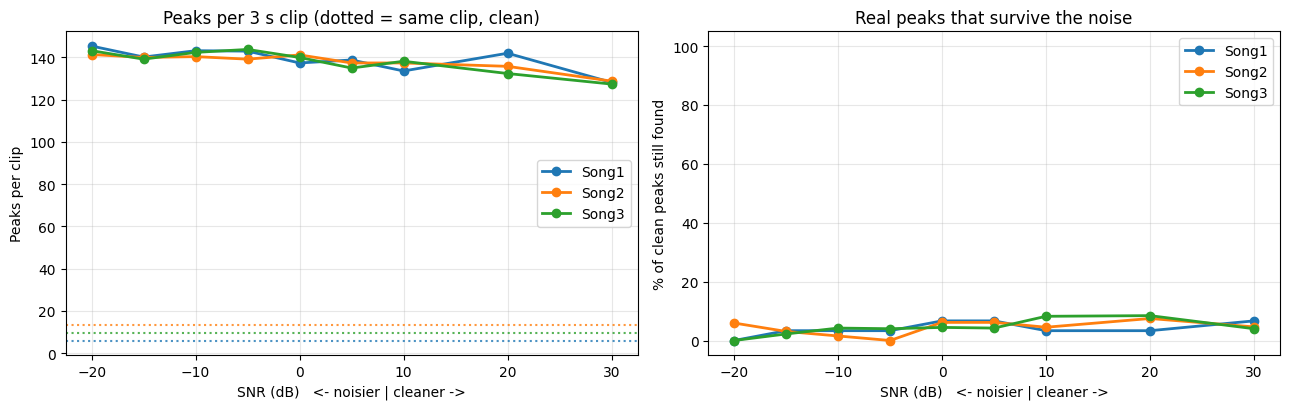

Mean peaks per clip and % surviving, by noise level:
        noisy_peaks  survived_pct
snr_db                           
 30           128.1           5.1
 20           136.7           6.4
 10           136.4           5.4
 5            137.1           5.7
 0            139.5           5.8
-5            142.0           2.4
-10           142.0           3.0
-15           139.8           2.9
-20           143.3           2.0


In [103]:
mech_rng = np.random.default_rng(T9_SEED + 200)   # separate generator, main results unaffected
rows = []
for song, (y, sr) in songs.items():
    max_start = len(y) / sr - T9_LENGTH_SEC
    for frac in np.linspace(0, 1, 5):                                  # 5 clips spread through the song
        clip, _ = make_query(y, sr, frac * max_start, T9_LENGTH_SEC)   # clean clip, no transform
        _, clean_peaks, _ = viewer.extract_fingerprints(clip)
        clean_set = {(f, t) for f, t, _ in clean_peaks}                # positions of the real peaks
        for snr in T9_SNR_LEVELS_DB:
            _, noisy_peaks, _ = viewer.extract_fingerprints(add_white_noise(clip, snr, mech_rng))
            noisy_set = {(f, t) for f, t, _ in noisy_peaks}
            rows.append({
                "song": song, "snr_db": snr,
                "clean_peaks": len(clean_set), "noisy_peaks": len(noisy_set),
                # share of the real peaks still present at exactly the same (bin, frame)
                "survived_pct": 100 * len(clean_set & noisy_set) / len(clean_set) if clean_set else np.nan,
            })
mech = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for song, g in mech.groupby("song"):
    by_snr = g.groupby("snr_db")
    line, = axes[0].plot(by_snr["noisy_peaks"].mean().index, by_snr["noisy_peaks"].mean().values,
                         "o-", lw=2, label=song)
    axes[0].axhline(g["clean_peaks"].mean(), color=line.get_color(), ls=":", alpha=0.8)
    axes[1].plot(by_snr["survived_pct"].mean().index, by_snr["survived_pct"].mean().values,
                 "o-", lw=2, label=song)

axes[0].set_title("Peaks per 3 s clip (dotted = same clip, clean)")
axes[0].set_ylabel("Peaks per clip")
axes[1].set_title("Real peaks that survive the noise")
axes[1].set_ylabel("% of clean peaks still found")
axes[1].set_ylim(-5, 105)
for ax in axes:
    ax.set_xlabel("SNR (dB)   <- noisier | cleaner ->")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig("task9_peak_mechanism.png", dpi=150)
plt.show()

print("Mean peaks per clip and % surviving, by noise level:")
print(mech.groupby("snr_db")[["noisy_peaks", "survived_pct"]].mean().sort_index(ascending=False).round(1))

## 9.11 Headline summary (computed from the results above)
Every number below is calculated from `results_t9`, so it stays correct if the settings change.
The same table is saved as `task9_summary.csv` for Task 10's final comparison.

In [104]:
summary_rows = []
for m in METHODS:
    d = results_t9[results_t9["method"] == m]
    acc_by_snr = d[np.isfinite(d["snr_db"])].groupby("snr_db")["correct"].mean()
    reliable_from = min_reliable_x(acc_by_snr, RELIABLE_ACCURACY)       # Task 8's helper (None = never reliable)
    lowest = d[d["snr_db"] == min(T9_SNR_LEVELS_DB)]
    top_guess = lowest["pred"].where(lowest["pred"].notna(), "no match").value_counts(normalize=True)
    summary_rows.append({
        "method": m,
        "clean accuracy (%)": round(100 * d[np.isinf(d["snr_db"])]["correct"].mean(), 1),
        f"reliable (>= {RELIABLE_ACCURACY:.0%}) down to": (f"{reliable_from:g} dB" if reliable_from is not None
                                                          else "never, with any noise"),
        "accuracy at 0 dB (%)": round(100 * acc_by_snr.get(0, np.nan), 1),
        f"accuracy at {min(T9_SNR_LEVELS_DB)} dB (%)": round(100 * acc_by_snr.loc[min(T9_SNR_LEVELS_DB)], 1),
        # largest share of answers going to one song (about 33% = guesses still evenly spread over the 3 songs)
        f"most common guess at {min(T9_SNR_LEVELS_DB)} dB": f"{top_guess.index[0]} ({100 * top_guess.iloc[0]:.0f}%)",
    })
t9_summary = pd.DataFrame(summary_rows).set_index("method")
t9_summary.to_csv("task9_summary.csv")
print(t9_summary.T.to_string())

# Which song breaks first under noise for each method (the song whose reliability ends at the cleanest level).
print()
for m in METHODS:
    d = results_t9[(results_t9["method"] == m) & np.isfinite(results_t9["snr_db"])]
    for song, g in d.groupby("song"):
        r = min_reliable_x(g.groupby("snr_db")["correct"].mean(), RELIABLE_ACCURACY)
        verdict = f"reliable down to {r:g} dB" if r is not None else f"never reaches {RELIABLE_ACCURACY:.0%} with noise"
        print(f"{m:10s} {song}: {verdict}")

method                          baseline              peak_pair
clean accuracy (%)                 100.0                  100.0
reliable (>= 90%) down to         -20 dB  never, with any noise
accuracy at 0 dB (%)               100.0                   62.2
accuracy at -20 dB (%)             100.0                   42.2
most common guess at -20 dB  Song1 (33%)         no match (58%)

baseline   Song1: reliable down to -20 dB
baseline   Song2: reliable down to -20 dB
baseline   Song3: reliable down to -20 dB
peak_pair  Song1: never reaches 90% with noise
peak_pair  Song2: never reaches 90% with noise
peak_pair  Song3: never reaches 90% with noise


## 9.12 Discussion - results of the submitted run
All numbers below come from this notebook's run. The noise is seeded and the clips are fixed, so re-running the
notebook reproduces them exactly. Each accuracy is over 45 queries per method and noise level (3 songs x 15 start
positions), so one query = 2.2 percentage points; per song, one query = 6.7 points.

| Noise level | clean | 30 dB | 20 dB | 10 dB | 5 dB | 0 dB | -5 dB | -10 dB | -15 dB | -20 dB |
|---|---|---|---|---|---|---|---|---|---|---|
| Peak-pair accuracy (%) | 97.8 | 97.8 | 97.8 | 100 | 100 | 97.8 | 100 | 100 | 91.1 | 73.3 |
| Baseline accuracy (%) | 91.1 | 91.1 | 91.1 | 91.1 | 93.3 | 91.1 | 91.1 | 88.9 | 88.9 | 73.3 |
| Peak-pair margin | 0.97 | 0.97 | 0.98 | 0.95 | 0.95 | 0.93 | 0.90 | 0.81 | 0.65 | 0.24 |
| Baseline margin | 0.26 | 0.25 | 0.26 | 0.27 | 0.28 | 0.29 | 0.29 | 0.29 | 0.28 | 0.34 |
| % of clean peaks still found (Visual 5) | - | 88.3 | 77.0 | 59.8 | 48.4 | 39.1 | 27.4 | 18.1 | 9.9 | 4.0 |

**Peak-pair stays reliable down to -15 dB.** Its accuracy stays between 97.8% and 100% from clean audio down to
-10 dB (noise 10 times stronger than the music), drops to 91.1% at -15 dB and to 73.3% at -20 dB. The small ups and
downs above -15 dB are single queries (2.2 points each).

**It survives because only a few fingerprints are needed.** At -10 dB only 18.1% of the clean peaks are still found
and the average votes for the winning song fall from 158-272 (clean, depending on the song) to 10-21, yet accuracy is
still 100%: the true matches still line up at one time offset, while accidental matches scatter. The margin shows the
limit approaching before accuracy drops: 0.97 clean, 0.81 at -10 dB, 0.65 at -15 dB, and 0.24 at -20 dB, where only
4.0% of the clean peaks survive and the winning song gets just 1.4-1.7 votes.

**Song3 breaks first for peak-pair.** It is reliable down to -10 dB (86.7% at -15 dB, 53.3% at -20 dB), while Song1
and Song2 stay reliable down to -15 dB. Song3 also has the fewest votes under heavy noise (10.1 at -10 dB, against
21.4 for Song1 and 11.7 for Song2).

**The baseline's limit comes from its lower starting accuracy, not from a stronger reaction to noise.** Its accuracy
barely changes from clean audio (91.1%) down to -5 dB (91.1%) and -10 dB (88.9%), and its margin stays at 0.25-0.29.
It crosses the 90% line already at -10 dB because it starts only just above it: Song2 and Song3 are at 86.7% even
without noise and never reach 90%. Only Song1 is reliable for the baseline, down to -15 dB.

**At -20 dB both methods fall to 73.3%.** Neither method drifts towards always guessing one song (Visual 4): the
largest share of answers going to a single song is 36% for the baseline and 42% for peak-pair (both Song2), close to
the fair share of 33%. The wrong answers are spread over the other songs (confusion tables in 9.9).

**One peak-pair query had no answer at all** (no matching hash) on clean audio and at 30 dB; every other query got an
answer. That missing answer is the one clean miss for peak-pair.

### Summary
Under white noise, peak-pair is the more accurate method at every level down to -15 dB and keeps a far higher
confidence margin (0.93 against 0.29 at 0 dB). The baseline is almost unaffected by noise down to -10 dB, but its
accuracy ceiling (about 91%) is lower. At -20 dB (noise 100 times stronger than the music) both methods are at 73.3%.

### Limitations
* White noise is not real-world noise; crowd chatter or traffic concentrate their energy at particular frequencies.
* Three songs, 3 s clips, one noise sample per start position (15 per song and noise level).

# Group 3 - Task 10: Transformation robustness and final comparison

**Goal:** test what happens when the music itself is altered - **pitch shifting** (played higher or lower at the
same speed) and **time stretching** (played faster or slower at the same pitch) - and then **compare the two
recognition methods across every experiment of Tasks 8, 9 and 10**: where each one succeeds and where it fails.

**Run this AFTER all earlier cells** (Runtime -> Run all). It reuses, without changing them:
`songs`, `METHODS`, `TRANSFORMS`, `make_query`, `run_experiment`, `min_reliable_x`, `RELIABLE_ACCURACY`,
`ShazamPeakPairRecogniser`, `SAMPLE_COUNT`, `HOP_LENGTH`, and for the final comparison
`results` (Task 8) and `results_t9` (Task 9).

### Experiment design
| Decision | Choice | Why |
|---|---|---|
| Pitch shift | -2, -1, -0.5, -0.25, 0, +0.25, +0.5, +1, +2 semitones | 1 semitone = one piano key (about 6% in frequency); small steps near 0 find exactly where matching breaks |
| Time stretch | speed x0.80, 0.90, 0.95, 0.98, 1.00, 1.02, 1.05, 1.10, 1.25 | 1.10 = 10% faster, 0.90 = 10% slower; again finer near the original speed |
| Query length | 3 s before transforming, 15 starts per song | Same clips as Task 9, so the untransformed (0 / 1.00) condition reproduces Task 8 and Task 9 exactly |
| "Correct" | `pred == song` (Task 8's convention) | Keeps Tasks 8, 9 and 10 comparable |
| Tools | `librosa.effects.pitch_shift`, `librosa.effects.time_stretch` | Standard, high-quality implementations |

**Note on time stretching:** the 3 s clip is cut first and then stretched, so the *musical content* is the same
3 s of the song, but its *duration* changes (speed x0.80 -> 3.75 s, speed x1.25 -> 2.4 s).

**Reading "tolerance":** for each method, the range of pitch shifts (or speeds) around the original over which
accuracy stays at or above 90%. Wider = more robust.

### Visual indicators produced
1. **Accuracy vs pitch shift and vs speed** - for both methods.
2. **Confidence margin vs pitch shift and vs speed.**
3. **Peak-pair votes vs pitch shift and vs speed.**
4. **Mechanism** - the peaks before/after a small pitch shift, and how many hashes survive each transformation.
5. **Final comparison across Tasks 8, 9 and 10** - one table and one chart: where each method succeeds or fails.

## 10.1 Setup, settings and the two transformations

In [105]:
# ============================================================
# GROUP 3 - TASK 10: TRANSFORMATION ROBUSTNESS AND FINAL COMPARISON
# This code assumes that every earlier cell (Tasks 1-6, Task 8 and Task 9) has already run.
# It REUSES these names (nothing in them is changed):
#   songs, METHODS, TRANSFORMS, make_query, run_experiment     (Group 1 / Task 8)
#   min_reliable_x, RELIABLE_ACCURACY                           (Task 8)
#   ShazamPeakPairRecogniser, SAMPLE_COUNT, HOP_LENGTH          (Task 6) - only to look at peaks / hashes
#   results (Task 8) and results_t9 (Task 9)                    - only in the final comparison (10.8)
# ============================================================
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from IPython.display import Audio, display

for _needed in ["songs", "METHODS", "TRANSFORMS", "make_query", "run_experiment", "min_reliable_x",
                "RELIABLE_ACCURACY", "N_STARTS", "ShazamPeakPairRecogniser", "SAMPLE_COUNT", "HOP_LENGTH"]:
    assert _needed in globals(), f"'{_needed}' not found - run all the earlier cells first."

# ---- experiment settings ----
T10_PITCH_STEPS = [-2, -1, -0.5, -0.25, 0, 0.25, 0.5, 1, 2]           # semitones (0 = original pitch)
T10_STRETCH_RATES = [0.80, 0.90, 0.95, 0.98, 1.00, 1.02, 1.05, 1.10, 1.25]  # speed factor (1.00 = original)
T10_LENGTH_SEC = 3          # same 3 s clips as Task 9 (see Task 9's design table for why)
T10_N_STARTS = N_STARTS     # same 15 start positions per song as Tasks 8 and 9


def pitch_shift_clip(clip, sr, n_steps):
    """Shift every frequency by n_steps semitones, keeping the speed. 0 -> untouched copy."""
    if n_steps == 0:
        return clip.copy()
    with warnings.catch_warnings():
        # pitch_shift uses time_stretch internally; see the note in time_stretch_clip below.
        warnings.simplefilter("ignore", FutureWarning)
        # librosa 1.0's internal resampler can also print "invalid value encountered in cast"; it was checked
        # that the output contains no invalid values (no NaN / inf), so this message is hidden too.
        warnings.filterwarnings("ignore", message="invalid value encountered in cast")
        return librosa.effects.pitch_shift(clip, sr=sr, n_steps=n_steps)


def time_stretch_clip(clip, sr, rate):
    """Play the clip `rate` times as fast, keeping the pitch (1.10 = 10% faster). 1.0 -> untouched copy."""
    if rate == 1.0:
        return clip.copy()
    with warnings.catch_warnings():
        # librosa 1.0 prints a FutureWarning about two unused internal parameters on every call; it does not
        # affect the result, so it is hidden to keep the output readable.
        warnings.simplefilter("ignore", FutureWarning)
        warnings.filterwarnings("ignore", message="invalid value encountered in cast")
        return librosa.effects.time_stretch(clip, rate=rate)


# Register both in Task 8's hook, exactly as Task 9 registered "snr_db".
# make_query calls TRANSFORMS[name](clip, sr, value) for every condition key it is given.
TRANSFORMS["pitch_steps"] = pitch_shift_clip
TRANSFORMS["stretch"] = time_stretch_clip
print("Registered transforms:", list(TRANSFORMS))


def tolerance_range(acc, neutral, threshold=RELIABLE_ACCURACY):
    """Widest range of settings around `neutral` (0 semitones / speed 1.0) where accuracy stays >= threshold.

    Walks outwards from the neutral value in both directions and stops at the first failure.
    Returns (low, high), or None if the method is not reliable even without any transformation.
    `acc` is a Series: index = setting, value = accuracy.
    """
    acc = acc.sort_index()
    values = list(acc.index)
    if neutral not in values or acc[neutral] < threshold:
        return None
    i = values.index(neutral)
    low = high = neutral
    for v in reversed(values[:i]):        # walk downwards (more negative / slower)
        if acc[v] >= threshold:
            low = v
        else:
            break
    for v in values[i + 1:]:              # walk upwards (more positive / faster)
        if acc[v] >= threshold:
            high = v
        else:
            break
    return low, high

Registered transforms: ['snr_db', 'pitch_steps', 'stretch']


## 10.2 Sanity checks
1. **Did the transformations do what they claim?** The pitch shift should leave the duration unchanged; the time
   stretch should change it by exactly 1 / speed.
2. **Listen** to the same clip at the original pitch, +1 semitone, and 10% faster.

In [106]:
demo_name = "Song2" if "Song2" in songs else list(songs)[0]
demo_y, demo_sr = songs[demo_name]
demo_clip, _ = make_query(demo_y, demo_sr, start_sec=10.0, length_sec=T10_LENGTH_SEC)   # untransformed clip

print(f"Original clip: {len(demo_clip) / demo_sr:.3f} s")
for n in [-1, 1]:
    out = pitch_shift_clip(demo_clip, demo_sr, n)
    print(f"pitch {n:+g} semitone : {len(out) / demo_sr:.3f} s  (expected {len(demo_clip) / demo_sr:.3f} s)")
for r in [0.9, 1.1]:
    out = time_stretch_clip(demo_clip, demo_sr, r)
    print(f"speed x{r:.2f}       : {len(out) / demo_sr:.3f} s  (expected {len(demo_clip) / demo_sr / r:.3f} s)")

# Pitch check: the strongest frequency should move up by about 2**(1/12) = 1.059 for +1 semitone.
def strongest_freq(clip, sr):
    spectrum = np.abs(np.fft.rfft(clip))
    return np.fft.rfftfreq(len(clip), 1 / sr)[np.argmax(spectrum)]
f0 = strongest_freq(demo_clip, demo_sr)
f1 = strongest_freq(pitch_shift_clip(demo_clip, demo_sr, 1), demo_sr)
print(f"\nStrongest frequency: {f0:.1f} Hz -> {f1:.1f} Hz after +1 semitone "
      f"(ratio {f1 / f0:.3f}, expected {2 ** (1 / 12):.3f})")

for label, clip in [("original", demo_clip),
                    ("+1 semitone", pitch_shift_clip(demo_clip, demo_sr, 1)),
                    ("10% faster", time_stretch_clip(demo_clip, demo_sr, 1.1))]:
    print(f"{demo_name}, {label}:")
    display(Audio(clip, rate=demo_sr))

Original clip: 3.000 s
pitch -1 semitone : 3.000 s  (expected 3.000 s)
pitch +1 semitone : 3.000 s  (expected 3.000 s)
speed x0.90       : 3.333 s  (expected 3.333 s)
speed x1.10       : 2.727 s  (expected 2.727 s)

Strongest frequency: 880.0 Hz -> 932.3 Hz after +1 semitone (ratio 1.059, expected 1.059)
Song2, original:


Song2, +1 semitone:


Song2, 10% faster:


## 10.3 The experiments
Two calls to Task 8's `run_experiment`: one sweeping the pitch, one sweeping the speed. The results are combined
into one table `results_t10` with two extra columns: `transform` ("pitch" or "stretch") and `value`
(semitones, or speed factor). The untransformed condition is checked against Task 9's clean results:
the clips are identical, so the accuracy must match exactly.

In [107]:
t0 = time.time()
res_pitch = run_experiment(songs, METHODS, [T10_LENGTH_SEC], T10_N_STARTS,
                           conditions=[{"pitch_steps": n} for n in T10_PITCH_STEPS])
res_pitch["transform"], res_pitch["value"] = "pitch", res_pitch["pitch_steps"]
print(f"Pitch sweep:   {len(res_pitch)} rows in {time.time() - t0:.0f} s")

t0 = time.time()
res_stretch = run_experiment(songs, METHODS, [T10_LENGTH_SEC], T10_N_STARTS,
                             conditions=[{"stretch": r} for r in T10_STRETCH_RATES])
res_stretch["transform"], res_stretch["value"] = "stretch", res_stretch["stretch"]
print(f"Stretch sweep: {len(res_stretch)} rows in {time.time() - t0:.0f} s")

results_t10 = pd.concat([res_pitch, res_stretch], ignore_index=True)
results_t10.to_csv("task10_results.csv", index=False)   # Task 8's columns + pitch_steps / stretch, transform, value
print(f"Saved {len(results_t10)} rows to task10_results.csv")

# ---- Check: untransformed queries must give the same accuracy as Task 9's clean condition ----
neutral = results_t10[((results_t10["transform"] == "pitch") & (results_t10["value"] == 0)) |
                      ((results_t10["transform"] == "stretch") & (results_t10["value"] == 1.0))]
check = neutral.pivot_table(index="method", columns="transform", values="correct", aggfunc="mean")
if "results_t9" in globals():
    check["Task 9 clean"] = results_t9[np.isinf(results_t9["snr_db"])].groupby("method")["correct"].mean()
print("\nUntransformed accuracy (all columns should be identical):")
print(check.round(3))
print("-> MATCH" if np.allclose(check.values, check.values[:, [0]]) else "-> MISMATCH: check settings")

Pitch sweep:   810 rows in 21 s
Stretch sweep: 810 rows in 19 s
Saved 1620 rows to task10_results.csv

Untransformed accuracy (all columns should be identical):
transform  pitch  stretch  Task 9 clean
method                                 
baseline     1.0      1.0           1.0
peak_pair    1.0      1.0           1.0
-> MATCH


## 10.4 Results tables

In [108]:
for t, unit in [("pitch", "semitones"), ("stretch", "speed factor")]:
    d = results_t10[results_t10["transform"] == t]
    print(f"===== {t.upper()} ({unit}) =====")
    print("Accuracy (%) by method:")
    print((d.pivot_table(index="value", columns="method", values="correct", aggfunc="mean") * 100).round(1))
    print("\nAccuracy (%) by method and song:")
    print((d.pivot_table(index="value", columns=["method", "song"], values="correct", aggfunc="mean") * 100).round(1))
    print("\nAverage confidence margin:")
    print(d.pivot_table(index="value", columns="method", values="margin", aggfunc="mean").round(2))
    print("\nPeak-pair: average votes for the winning song:")
    print(d[d["method"] == "peak_pair"].pivot_table(index="value", columns="song", values="score",
                                                    aggfunc="mean").round(1))
    print()

print("Tolerance = range around the original where accuracy stays >= "
      f"{RELIABLE_ACCURACY:.0%} (None = not reliable even untransformed):")
for t, neutral_value in [("pitch", 0), ("stretch", 1.0)]:
    for m in METHODS:
        acc = results_t10[(results_t10["transform"] == t) & (results_t10["method"] == m)] \
            .groupby("value")["correct"].mean()
        print(f"  {t:8s} {m:10s}: {tolerance_range(acc, neutral_value)}")

===== PITCH (semitones) =====
Accuracy (%) by method:
method  baseline  peak_pair
value                      
-2.00      100.0        0.0
-1.00      100.0        0.0
-0.50      100.0       13.3
-0.25      100.0       33.3
 0.00      100.0      100.0
 0.25      100.0       24.4
 0.50      100.0        0.0
 1.00      100.0        0.0
 2.00      100.0        0.0

Accuracy (%) by method and song:
method baseline               peak_pair              
song      Song1  Song2  Song3     Song1  Song2  Song3
value                                                
-2.00     100.0  100.0  100.0       0.0    0.0    0.0
-1.00     100.0  100.0  100.0       0.0    0.0    0.0
-0.50     100.0  100.0  100.0      40.0    0.0    0.0
-0.25     100.0  100.0  100.0     100.0    0.0    0.0
 0.00     100.0  100.0  100.0     100.0  100.0  100.0
 0.25     100.0  100.0  100.0      73.3    0.0    0.0
 0.50     100.0  100.0  100.0       0.0    0.0    0.0
 1.00     100.0  100.0  100.0       0.0    0.0    0.0
 2.00     

## 10.5 Visual 1 - Accuracy vs pitch shift and vs speed
Thick lines = all queries pooled per method; thin dashed lines = individual songs (same colour as their method).
Dotted line = chance (guessing among the 3 songs); dashed green line = the 90% "reliable" bar.
The original audio is at **0 semitones** (left panel) and **speed 1.00** (right panel), marked by the grey vertical line.

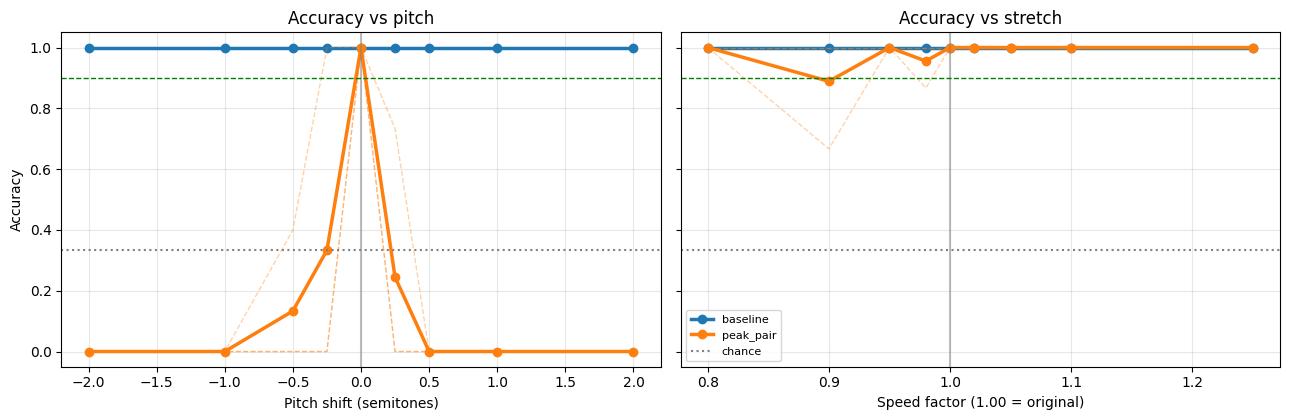

In [109]:
T10_PANELS = [("pitch", 0, "Pitch shift (semitones)"), ("stretch", 1.0, "Speed factor (1.00 = original)")]
METHOD_COLOURS = {m: c for m, c in zip(METHODS, ["tab:blue", "tab:orange", "tab:green", "tab:red"])}


def plot_t10_metric(column, ylabel, title, save_as, ylim=None, per_song=False):
    """One panel per transformation; one line per method (and optionally thin lines per song)."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
    for ax, (t, neutral_value, xlabel) in zip(axes, T10_PANELS):
        d = results_t10[results_t10["transform"] == t]
        for m in METHODS:
            dm = d[d["method"] == m]
            if per_song:
                for song, g in dm.groupby("song"):
                    s = g.groupby("value")[column].mean()
                    ax.plot(s.index, s.values, "--", color=METHOD_COLOURS[m], alpha=0.35, lw=1)
            s = dm.groupby("value")[column].mean()
            ax.plot(s.index, s.values, "o-", color=METHOD_COLOURS[m], lw=2.5, label=m)
        ax.axvline(neutral_value, color="gray", alpha=0.5)
        if column == "correct":
            ax.axhline(1 / len(songs), color="gray", ls=":", label="chance")
            ax.axhline(RELIABLE_ACCURACY, color="green", ls="--", lw=1)
        ax.set_xlabel(xlabel)
        ax.set_title(title.format(t=t))
        ax.grid(alpha=0.3)
        if ylim:
            ax.set_ylim(*ylim)
    axes[0].set_ylabel(ylabel)
    axes[-1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(save_as, dpi=150)
    plt.show()


plot_t10_metric("correct", "Accuracy", "Accuracy vs {t}", "task10_accuracy.png", ylim=(-0.05, 1.05), per_song=True)

## 10.6 Visual 2 and 3 - Confidence margin and peak-pair votes
Margin: 1 = the winner is far ahead, 0 = the runner-up is tied. Votes: matching hashes at the winning time offset;
the dotted line is the same song with no transformation.

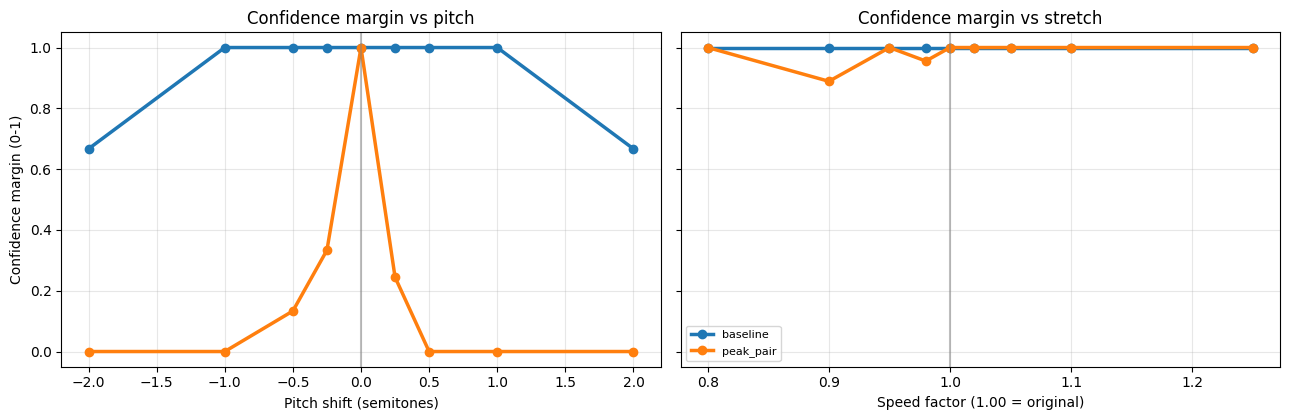

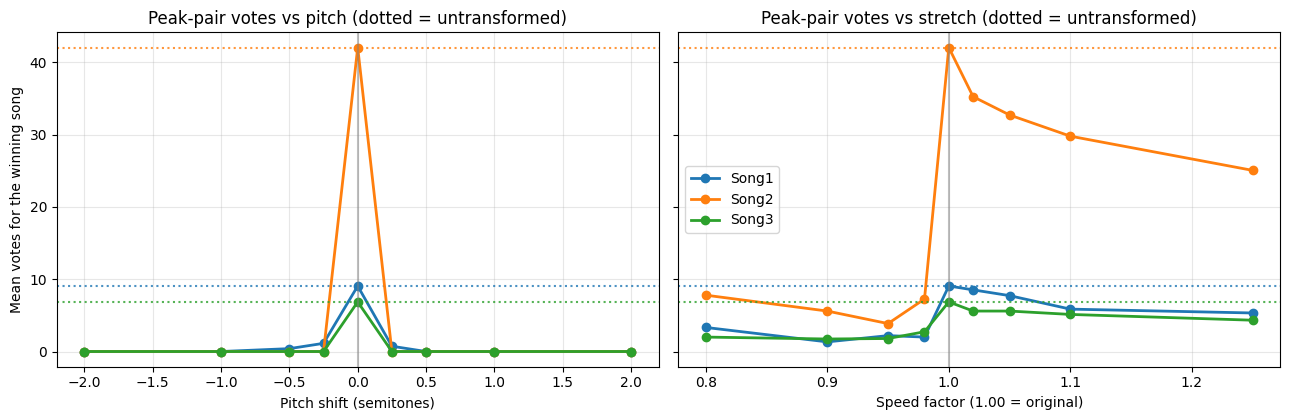

In [110]:
plot_t10_metric("margin", "Confidence margin (0-1)", "Confidence margin vs {t}", "task10_margin.png", ylim=(-0.05, 1.05))

# Peak-pair votes, one line per song.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
pp_t10 = results_t10[results_t10["method"] == "peak_pair"]
for ax, (t, neutral_value, xlabel) in zip(axes, T10_PANELS):
    d = pp_t10[pp_t10["transform"] == t]
    for song, g in d.groupby("song"):
        votes = g.groupby("value")["score"].mean()
        line, = ax.plot(votes.index, votes.values, "o-", lw=2, label=song)
        ax.axhline(votes.get(neutral_value, np.nan), color=line.get_color(), ls=":", alpha=0.8)
    ax.axvline(neutral_value, color="gray", alpha=0.5)
    ax.set_xlabel(xlabel)
    ax.set_title(f"Peak-pair votes vs {t} (dotted = untransformed)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean votes for the winning song")
axes[-1].legend()
fig.tight_layout()
fig.savefig("task10_votes.png", dpi=150)
plt.show()

## 10.7 Visual 4 - Mechanism: what the transformations do to the fingerprints
Peak-pair matching looks up each hash `(frequency 1, frequency 2, time gap)` **exactly**. So:
* **Left:** the peaks of one clip before and after a +0.5 semitone shift. Each peak moves up by about 3% in
  frequency; to the eye they almost overlap, but many land in a different frequency bin.
* **Right:** for 5 clips per song, the share of the clip's hash keys that are **still exactly the same** after each
  transformation. Pitch shift changes the two frequencies; time stretch changes the time gap.

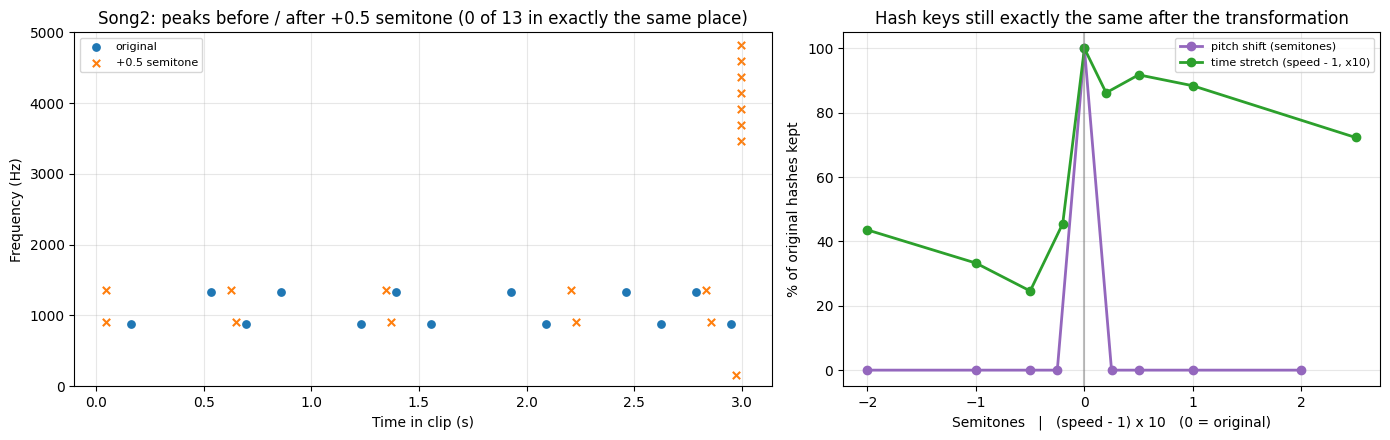

Mean % of hash keys kept, pitch (semitones):
value
-2.00      0.0
-1.00      0.0
-0.50      0.0
-0.25      0.0
 0.00    100.0
 0.25      0.0
 0.50      0.0
 1.00      0.0
 2.00      0.0

Mean % of hash keys kept, stretch (speed factor):
value
0.80     43.6
0.90     33.3
0.95     24.6
0.98     45.5
1.00    100.0
1.02     86.2
1.05     91.8
1.10     88.4
1.25     72.3



In [111]:
viewer10 = ShazamPeakPairRecogniser()   # used only to extract peaks and hashes, no database needed
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})

# ---- Left: constellation before / after +0.5 semitone ----
_, peaks_orig, _ = viewer10.extract_fingerprints(demo_clip)
_, peaks_shift, _ = viewer10.extract_fingerprints(pitch_shift_clip(demo_clip, demo_sr, 0.5))
for peaks, colour, marker, label in [(peaks_orig, "tab:blue", "o", "original"),
                                     (peaks_shift, "tab:orange", "x", "+0.5 semitone")]:
    if peaks:
        f_bins = np.array([p[0] for p in peaks])
        t_frames = np.array([p[1] for p in peaks])
        axes[0].scatter(librosa.frames_to_time(t_frames, sr=demo_sr, hop_length=HOP_LENGTH),
                        f_bins * demo_sr / SAMPLE_COUNT, s=28, c=colour, marker=marker, label=label)
same = len({(f, t) for f, t, _ in peaks_orig} & {(f, t) for f, t, _ in peaks_shift})
axes[0].set_title(f"{demo_name}: peaks before / after +0.5 semitone "
                  f"({same} of {len(peaks_orig)} in exactly the same place)")
axes[0].set_xlabel("Time in clip (s)")
axes[0].set_ylabel("Frequency (Hz)")
axes[0].set_ylim(0, 5000)
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# ---- Right: % of hash keys that survive each transformation ----
rows = []
for song, (y, sr) in songs.items():
    max_start = len(y) / sr - T10_LENGTH_SEC
    for frac in np.linspace(0, 1, 5):                                   # 5 clips spread through the song
        clip, _ = make_query(y, sr, frac * max_start, T10_LENGTH_SEC)
        orig_keys = {h for h, _ in viewer10.extract_fingerprints(clip)[0]}
        if not orig_keys:
            continue
        for t, values, fn in [("pitch", T10_PITCH_STEPS, pitch_shift_clip),
                              ("stretch", T10_STRETCH_RATES, time_stretch_clip)]:
            for v in values:
                new_keys = {h for h, _ in viewer10.extract_fingerprints(fn(clip, sr, v))[0]}
                rows.append({"song": song, "transform": t, "value": v,
                             "hashes_kept_pct": 100 * len(orig_keys & new_keys) / len(orig_keys)})
hash_survival = pd.DataFrame(rows)

for t, colour, label in [("pitch", "tab:purple", "pitch shift (semitones)"),
                         ("stretch", "tab:green", "time stretch (speed - 1, x10)")]:
    s = hash_survival[hash_survival["transform"] == t].groupby("value")["hashes_kept_pct"].mean()
    # Put both on one axis: pitch in semitones, stretch as (speed - 1) x 10, so 0.9 -> -1 and 1.1 -> +1.
    x = s.index if t == "pitch" else (s.index - 1.0) * 10
    axes[1].plot(x, s.values, "o-", lw=2, color=colour, label=label)
axes[1].axvline(0, color="gray", alpha=0.5)
axes[1].set_title("Hash keys still exactly the same after the transformation")
axes[1].set_xlabel("Semitones   |   (speed - 1) x 10   (0 = original)")
axes[1].set_ylabel("% of original hashes kept")
axes[1].set_ylim(-5, 105)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig("task10_mechanism.png", dpi=150)
plt.show()

for t, unit in [("pitch", "semitones"), ("stretch", "speed factor")]:
    print(f"Mean % of hash keys kept, {t} ({unit}):")
    print(hash_survival[hash_survival["transform"] == t].groupby("value")["hashes_kept_pct"].mean().round(1)
          .to_string())
    print()

## 10.8 Final comparison across Tasks 8, 9 and 10
This is the summary of the whole of Group 3: **where each method succeeds and where it fails.**
Every value is computed from `results` (Task 8), `results_t9` (Task 9) and `results_t10` (Task 10), and the
**"better"** column is decided by the numbers, not typed in. Saved as `group3_final_comparison.csv`.

In [112]:
def acc_where(df, method, **filters):
    """Mean accuracy (%) of `method` over the rows matching all filters (column=value or column=[values])."""
    d = df[df["method"] == method]
    for col, val in filters.items():
        d = d[d[col].isin(val)] if isinstance(val, (list, tuple)) else d[d[col] == val]
    return 100 * d["correct"].mean() if len(d) else np.nan


have_t8, have_t9 = "results" in globals(), "results_t9" in globals()
methods = list(METHODS)
comparison = []   # rows: (task, condition, {method: display text}, {method: number}, higher_is_better, failed)

def add_row(task, condition, numbers, display=None, higher_is_better=True, failed=None):
    """numbers = value used to decide the better method; failed(value) -> True if that method fails this test
    outright (e.g. 'never reliable'). If every method fails, the row is marked 'neither'."""
    display = display or {m: (f"{numbers[m]:.0f}%" if pd.notna(numbers[m]) else "n/a") for m in methods}
    comparison.append((task, condition, display, numbers, higher_is_better, failed))

# ---- Task 8: query length ----
if have_t8:
    for L in [1.0, 3.0]:
        add_row("Task 8", f"Accuracy, clean {L:g} s clips", {m: acc_where(results, m, length_sec=L) for m in methods})
    shortest = {}
    for m in methods:
        acc = results[results["method"] == m].groupby("length_sec")["correct"].mean()
        shortest[m] = min_reliable_x(acc, RELIABLE_ACCURACY)
    add_row("Task 8", f"Shortest reliable query (>= {RELIABLE_ACCURACY:.0%})",
            {m: (shortest[m] if shortest[m] is not None else np.inf) for m in methods},
            display={m: (f"{shortest[m]:g} s" if shortest[m] is not None else "never") for m in methods},
            higher_is_better=False, failed=np.isinf)

# ---- Task 9: noise ----
if have_t9:
    for snr in [0, -10]:
        add_row("Task 9", f"Accuracy with noise at {snr} dB SNR", {m: acc_where(results_t9, m, snr_db=snr) for m in methods})
    noisiest = {}
    for m in methods:
        d = results_t9[(results_t9["method"] == m) & np.isfinite(results_t9["snr_db"])]
        noisiest[m] = min_reliable_x(d.groupby("snr_db")["correct"].mean(), RELIABLE_ACCURACY)
    add_row("Task 9", f"Reliable (>= {RELIABLE_ACCURACY:.0%}) down to SNR",
            {m: (noisiest[m] if noisiest[m] is not None else np.inf) for m in methods},
            display={m: (f"{noisiest[m]:g} dB" if noisiest[m] is not None else "never, with any noise") for m in methods},
            higher_is_better=False, failed=np.isinf)

# ---- Task 10: pitch and stretch ----
for t, neutral_value, near, far, unit in [("pitch", 0, [-0.5, 0.5], [-1, 1], "semitone"),
                                          ("stretch", 1.0, [0.95, 1.05], [0.90, 1.10], "speed")]:
    d = results_t10[results_t10["transform"] == t]
    if t == "pitch":
        add_row("Task 10", "Accuracy at +/-0.5 semitone", {m: acc_where(d, m, value=near) for m in methods})
        add_row("Task 10", "Accuracy at +/-1 semitone", {m: acc_where(d, m, value=far) for m in methods})
    else:
        add_row("Task 10", "Accuracy at +/-5% speed", {m: acc_where(d, m, value=near) for m in methods})
        add_row("Task 10", "Accuracy at +/-10% speed", {m: acc_where(d, m, value=far) for m in methods})
    widths, texts = {}, {}
    for m in methods:
        acc = d[d["method"] == m].groupby("value")["correct"].mean()
        rng_ = tolerance_range(acc, neutral_value)
        widths[m] = (rng_[1] - rng_[0]) if rng_ else -1                 # wider range = more robust
        if rng_ is None:
            texts[m] = "not reliable"
        elif rng_[0] == rng_[1]:
            texts[m] = "only unshifted" if t == "pitch" else "only original speed"
        elif t == "pitch":
            texts[m] = f"{rng_[0]:+g} to {rng_[1]:+g} semitones"
        else:
            texts[m] = f"x{rng_[0]:.2f} to x{rng_[1]:.2f}"
    # width <= 0 means the method tolerates no change at all (or is not reliable even untransformed) -> fails
    add_row("Task 10", f"{t.capitalize()} tolerance (>= {RELIABLE_ACCURACY:.0%})", widths, display=texts,
            failed=lambda w: w <= 0)

# ---- build the table and decide the better method for each row ----
table_rows = []
for task, condition, display, numbers, higher, failed in comparison:
    vals = {m: numbers[m] for m in methods if pd.notna(numbers[m])}
    if failed is not None:
        vals = {m: v for m, v in vals.items() if not failed(v)}     # drop methods that fail outright
    if not vals:
        better = "neither"
    elif len(vals) == 1:
        better = next(iter(vals))
    elif len(set(vals.values())) == 1:
        better = "tie"
    else:
        better = (max if higher else min)(vals, key=vals.get)
    table_rows.append({"task": task, "condition": condition, **display, "better": better})
final_comparison = pd.DataFrame(table_rows).set_index(["task", "condition"])
final_comparison.to_csv("group3_final_comparison.csv")

pd.set_option("display.width", 200)
print(final_comparison.to_string())
if not (have_t8 and have_t9):
    print("\n(Run the Task 8 and Task 9 cells to include their rows.)")

print("\nRows won by each method:", final_comparison["better"].value_counts().to_dict())

                                                     baseline              peak_pair    better
task    condition                                                                             
Task 8  Accuracy, clean 1 s clips                        100%                    80%  baseline
        Accuracy, clean 3 s clips                        100%                   100%       tie
        Shortest reliable query (>= 90%)                0.5 s                    2 s  baseline
Task 9  Accuracy with noise at 0 dB SNR                  100%                    62%  baseline
        Accuracy with noise at -10 dB SNR                100%                    64%  baseline
        Reliable (>= 90%) down to SNR                  -20 dB  never, with any noise  baseline
Task 10 Accuracy at +/-0.5 semitone                      100%                     7%  baseline
        Accuracy at +/-1 semitone                        100%                     0%  baseline
        Pitch tolerance (>= 90%)           -2 to +

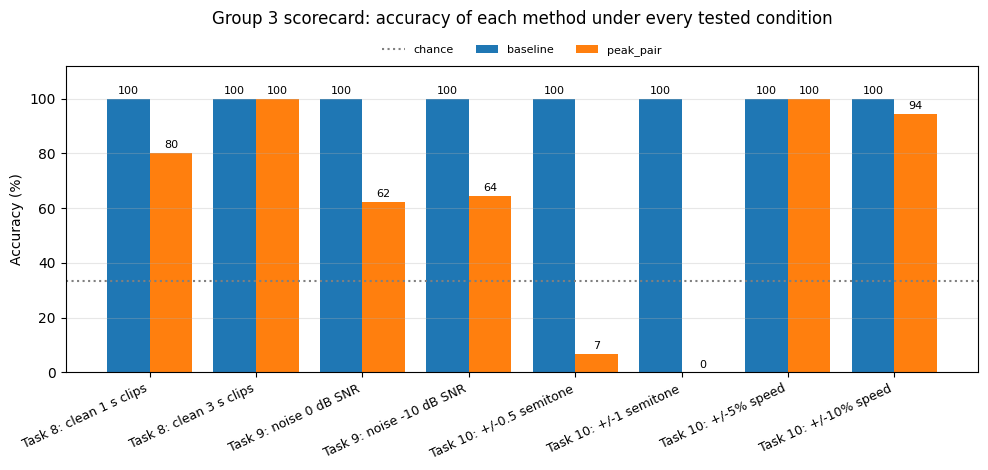

In [113]:
# ---- Visual 5: accuracy scorecard across all three tasks ----
# One pair of bars per condition (the accuracy rows of the table above), chance level dotted.
acc_rows = [(f"{task}: {cond}", numbers) for task, cond, _, numbers, _, _ in comparison if cond.startswith("Accuracy")]
labels = [r[0].replace("Accuracy, ", "").replace("Accuracy with noise at ", "noise ").replace("Accuracy at ", "")
          for r in acc_rows]
x = np.arange(len(acc_rows))
width = 0.8 / len(methods)

fig, ax = plt.subplots(figsize=(max(10, 1.25 * len(acc_rows)), 4.8))
for k, m in enumerate(methods):
    vals = [r[1][m] for r in acc_rows]
    bars = ax.bar(x + (k - (len(methods) - 1) / 2) * width, vals, width, color=METHOD_COLOURS[m], label=m)
    ax.bar_label(bars, labels=[f"{v:.0f}" if pd.notna(v) else "" for v in vals], fontsize=8, padding=2)
ax.axhline(100 / len(songs), color="gray", ls=":", label="chance")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 112)
ax.set_title("Group 3 scorecard: accuracy of each method under every tested condition", pad=30)
ax.legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(methods) + 1, frameon=False)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("group3_scorecard.png", dpi=150)
plt.show()

## 10.9 Discussion - results of the submitted run
All numbers below come from this notebook's run (Task 6 amended, see the check after Task 6). Each accuracy is over
45 queries per method and setting, so one query = 2.2 percentage points; chance level is 33%.

### Pitch shift: the peak-pair method fails, the baseline tolerates small shifts
| Pitch shift (semitones) | -2 | -1 | -0.5 | -0.25 | 0 | +0.25 | +0.5 | +1 | +2 |
|---|---|---|---|---|---|---|---|---|---|
| Peak-pair accuracy (%) | 57.8 | 33.3 | 37.8 | 53.3 | **97.8** | 57.8 | 37.8 | 37.8 | 64.4 |
| Baseline accuracy (%) | 77.8 | 44.4 | 82.2 | 91.1 | **91.1** | 91.1 | 84.4 | 62.2 | 66.7 |
| % of hash keys kept | 0.1 | 0.2 | 0.1 | 0.7 | 100 | 0.3 | 0.2 | 0.1 | 0.1 |

* **Peak-pair is reliable only on unshifted audio.** A quarter of a semitone already drops it to 53-58%, and
  +/-0.5 or +/-1 semitone gives 33-38%, which is chance level.
* **Why (measured in 10.7):** a hash is the exact triple (frequency bin 1, frequency bin 2, time gap). A pitch shift
  multiplies every frequency by the same factor (+1 semitone = x1.059), so peaks move to other frequency bins. For
  every shift tested, fewer than 1% of a clip's hash keys stay the same (0.1-0.7%). In the Song2 example, only 1 of
  126 peaks is in exactly the same place after +0.5 semitone. The winner's confidence margin falls from 0.97
  (unshifted) to 0.29-0.60.
* Some song/shift combinations score above chance (for example Song3 80% at +1 and +2 semitones). With fewer than 1%
  of hashes surviving on average, those answers rest on very few matching hashes, and the low margins show the
  runner-up close behind - they are not reliable recognitions.
* **The baseline tolerates +/-0.25 semitone** (91.1%) and stays at 82-84% at +/-0.5. It compares the overall
  spectral shape, which a small shift only slides slightly. Its accuracy depends strongly on the song and is not
  monotonic in the shift: Song1 stays at 100% from -0.5 to +2 semitones, while Song2 falls to 13.3% at +1 and 0% at
  -1 semitone.

### Time stretch: both methods hold up, but peak-pair's fingerprints thin out
| Speed factor | 0.80 | 0.90 | 0.95 | 0.98 | 1.00 | 1.02 | 1.05 | 1.10 | 1.25 |
|---|---|---|---|---|---|---|---|---|---|
| Peak-pair accuracy (%) | 95.6 | 97.8 | 97.8 | 97.8 | 97.8 | 97.8 | 97.8 | 97.8 | 95.6 |
| Baseline accuracy (%) | 91.1 | 91.1 | 91.1 | 91.1 | 91.1 | 93.3 | 91.1 | 93.3 | 91.1 |
| % of hash keys kept | 2.7 | 4.8 | 9.6 | 14.5 | 100 | 35.6 | 17.1 | 9.8 | 2.9 |
| Peak-pair margin | 0.50 | 0.74 | 0.85 | 0.91 | 0.97 | 0.95 | 0.89 | 0.81 | 0.55 |

* **Both methods stay above 90% over the whole tested range (x0.80 to x1.25).** Peak-pair is more accurate
  (95.6-97.8% against 91.1-93.3%).
* **But peak-pair works on far fewer fingerprints.** Stretching keeps the frequencies but changes every time gap, so
  only 2.7% of hash keys survive at x0.80 and 2.9% at x1.25. Its average votes fall from 158-272 (untransformed,
  depending on the song) to 2.0-3.9 at x0.80 and x1.25, and its margin from 0.97 to 0.50-0.55. It still names the
  right song, but on a handful of votes: the widest stretches tested are close to its limit.
* **The baseline is unaffected by speed:** its accuracy stays at 91.1-93.3% and its margin at 0.26 at every speed,
  because playing a clip faster or slower does not change which frequencies it contains on average.

### Final comparison across Tasks 8, 9 and 10 (table 10.8)
Peak-pair wins 6 rows, the baseline 5, and 1 is a tie.
* **Peak-pair is better** on clean 3 s clips (98% vs 91%), under noise (98% vs 91% at 0 dB, 100% vs 89% at -10 dB;
  reliable down to -15 dB vs -5 dB) and under speed changes (98% vs 91-92% at +/-5% and +/-10%). Note that the
  baseline's noise limit mainly reflects its lower starting accuracy: it is almost unaffected by noise down to -10 dB
  (see 9.12).
* **The baseline is better** on very short clips (91% vs 84% at 1 s; reliable from 1 s vs 2 s) and under pitch
  shift (83% vs 38% at +/-0.5 semitone, 53% vs 36% at +/-1 semitone; tolerates +/-0.25 semitone vs none).
* **Tie:** both tolerate the full tested speed range (x0.80 to x1.25).

**Conclusion.** The Shazam-style peak-pair method is the better recogniser of the *original recording*: it is
reliable from 2 s clips, 98% accurate on 3 s clips, and stays reliable under noise about 30 times stronger in power
than the music (-15 dB). Its weakness is any change of pitch, which breaks the exact-match hashes. The baseline is
less accurate on 3 s clips (91% vs 98%, with a confidence margin of only 0.26) but tolerates small pitch shifts and
very short clips, because it compares the overall spectral shape rather than exact peak positions.

### Limitations
* Three songs, so chance level is already 33%; a real recogniser must choose among millions of songs.
* The recognisers always name a song unless no hash matches at all, and no clip from a song *outside* the database
  was tested, so these results say nothing about false matches.
* Pitch shift and time stretch were applied digitally by librosa; real-world changes (a live cover, a DJ speeding up
  a track) are less clean.

### Possible improvement (not implemented)
Real recognisers make peak-pair matching tolerant to small changes, e.g. by storing *frequency ratios* instead of
absolute frequency bins (robust to pitch shift), or by matching hashes with a tolerance of +/- 1 bin or frame.